# Linguistic marker regional — rebuild kandidat
## SPEC
Seluruh GSM8K test (1.319 soal) dan seluruh split eksperimen ETHICS (1.514 soal), enam model × 17 persona.
Tujuan: final-only, pairing kanonis, coverage, count/density/presence, 52 kontras, efek dan Holm, PNG.
Bukan rerun API, perubahan scoring, perubahan persona, atau sinkronisasi Bab IV/VI.

## DESIGN PLAN
Baca JSON asli dan verifikasi isi soal/request. ETHICS boleh memakai cache pengukuran hanya setelah
hash final dan registry cocok; sampel cache dihitung ulang. Pertahankan ID+isi sah pada benturan
dengan remapping; tahan pasangan ambigu. Registry lama dibekukan dan kesalahan semantik yang diketahui
ditandai, bukan dinyatakan selesai. Analisis utama mencakup semua penjelasan, termasuk abstain.
Simpan output baru bertimestamp; arsipkan aset lama secara recoverable setelah pemeriksaan.

## IMPLEMENTATION
Sel berikut berisi sumber, pengukuran, statistik, sensitivitas, dan plotting langsung di notebook.
Modul ekstraksi yang telah ada diimpor secara eksplisit; tidak dibuat generator Python baru.
Run All menjalankan seluruh korpus dan dapat memerlukan waktu cukup lama.


In [1]:
BENCHMARK='GSM8K'
NOTEBOOK_NAME='linguistic_marker_regional_gsm8k.ipynb'
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import dataclasses, hashlib, itertools, json, math, os, re, shutil, sys, unicodedata, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, Patch
from scipy.stats import rankdata, wilcoxon, binomtest, chi2
from IPython.display import Image, display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'AGENTS.md').is_file() and (p/'result').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.core.linguistic_markers.registry import MarkerSpec, PatternSpec
from src.core.linguistic_markers.extractor import extract_markers
from src.core.linguistic_markers.surface import prepare_text_surface
from src.benchmarks.ethics.regional_lm_v3_extract import extract_response, registry_snapshot
from src.benchmarks.ethics.regional_ethics_presentation_view import classify_surface
from src.benchmarks.ethics.gender_lm_v2.surfaces import build_surfaces
ACTIVE=ROOT/'notebooks/regional/linguistic marker'/BENCHMARK
RUN_ID=datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN=ROOT/'result/linguistic_markers'/f'regional_{BENCHMARK.lower()}_raw_rebuild_{RUN_ID}'
RUN.mkdir(parents=True,exist_ok=False)
FIGURES=RUN/'figures'
FIGURES.mkdir()
SEED=20261005
LOW_SUPPORT=20
SCIENTIFIC_STATUS='candidate_known_marker_errors_no_rule_promotion'
MODELS=['meta-llama_llama-3.1-8b-instruct','meta-llama_llama-3.3-70b-instruct','mistralai_ministral-8b-2512','deepseek_deepseek-r1-distill-qwen-32b','openai_gpt-oss-20b','qwen_qwen3-next-80b-a3b-thinking']
MODEL_LABELS=dict(zip(MODELS,['Llama 3.1 8B','Llama 3.3 70B','Ministral 8B','DeepSeek R1 32B','GPT-OSS 20B','Qwen3 Next 80B']))
COLORS=dict(zip(MODELS,['#2463EB','#8038DC','#00946A','#D52C37','#C26A00','#007E99']))
IDENTITIES=['north_american','east_asian','south_asian','sub_saharan_african']
IDENTITY_LABELS=dict(zip(IDENTITIES,['Amerika Utara','Asia Timur','Asia Selatan','Afrika Sub-Sahara']))
SHORT_LABELS=dict(zip(IDENTITIES,['Am. Utara','As. Timur','As. Selatan','Afr. Sub-Sahara']))
CONDITIONS=['explicit','implicit_1','implicit_2','implicit_3']
CL=dict(zip(CONDITIONS,['E','I1','I2','I3']))
PERSONAS=['neutral']+[f'{i}_{c}' for i in IDENTITIES for c in CONDITIONS]
PL={'neutral':'N',**{f'{i}_{c}':f'{SHORT_LABELS[i]} {CL[c]}' for i in IDENTITIES for c in CONDITIONS}}
OLD_G=ROOT/'result/GMS8K/reports/Regional_Cultural_Persona/linguistic_markers/regional_gsm8k_full_source_aligned_v1_1_20260818'
OLD_E=ROOT/'result/ETHICS/reports/regional_lm_v3_20260916_r5'
OLD_E_PRESENTATION=ROOT/'result/ETHICS/reports/regional_ethics_presentation_20260919_r2'
SOURCE_AUDIT=ROOT/'result/linguistic_markers/regional_source_audit_20261005_095446_276443'
def sha(s): return hashlib.sha256(s.encode('utf-8')).hexdigest()
def normalized(s): return re.sub(r'\s+',' ',unicodedata.normalize('NFC',s or '')).strip()
def file_sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_table(frame,name): frame.to_csv(RUN/name,index=False,encoding='utf-8-sig')
if BENCHMARK=='GSM8K':
    registry_path=OLD_G/'marker_registry.csv'
    REGISTRY=pd.read_csv(registry_path,keep_default_na=False).to_dict('records')
    for m in REGISTRY:
        m['patterns']=json.loads(m['patterns'])
        m['benchmarks']=m['benchmarks'].split(';')
else:
    registry_path=OLD_E/'registry.json'
    REGISTRY=json.loads(registry_path.read_text(encoding='utf-8'))
def make_marker(m):
    fields={f.name for f in dataclasses.fields(MarkerSpec)}
    d={k:v for k,v in m.items() if k in fields}
    d['patterns']=tuple(PatternSpec(**{k:v for k,v in p.items() if k in ['pattern','note','flags']}) for p in d['patterns'])
    d['benchmarks']=tuple(d['benchmarks'])
    return MarkerSpec(**d)
MARKERS=tuple(make_marker(m) for m in REGISTRY)
MARKER_IDS=[m.marker_id for m in MARKERS]
REGISTRY_BY_ID={m.marker_id:m for m in MARKERS}
(RUN/'registry.json').write_text(json.dumps(REGISTRY,ensure_ascii=False,indent=2),encoding='utf-8')
COMMON=['organization_explicit_step','organization_bullet','organization_section_header','stance_hedge','stance_booster','stance_assumption','stance_self_correction','connective_causal','connective_contrastive','connective_conditional','self_reference_first_person','self_reference_inclusive_we','engagement_reader_directive','elaboration_code_gloss']
LABELS=dict(zip(COMMON,['Langkah awal baris','Bullet awal baris','Subjudul','Hedge','Booster','Asumsi eksplisit','Koreksi diri','Konektif kausal','Konektif kontras','Konektif kondisional','Rujukan orang pertama','We inklusif','Direktif pembaca','Elaborasi']))
LABELS.update(dict(zip([
'culture_region_north_american','culture_region_east_asian','culture_region_south_asian','culture_region_sub_saharan_african',
'culture_geocultural_broader_reference','culture_general_reference','culture_meta_framing','culture_relativist_framing',
'regional_persona_direct_address','regional_perspective_adoption','culture_collectivist_communal_orientation',
'culture_individual_autonomy_orientation','culture_family_obligation_orientation','culture_community_obligation_orientation',
'culture_reciprocity_interdependence_orientation','culture_hospitality_generosity_orientation','culture_elder_respect_orientation',
'culture_harmony_face_orientation','culture_hierarchy_authority_orientation','culture_named_concept_reference',
'culture_named_practice_reference','culture_warmup_name_echo','culture_identity_irrelevance'],[
'Label Amerika Utara','Label Asia Timur','Label Asia Selatan','Label Afrika Sub-Sahara','Rujukan geokultural lain',
'Rujukan budaya umum','Framing meta-budaya','Framing relativis','Sapaan persona regional','Adopsi perspektif regional',
'Orientasi komunal','Otonomi individu','Kewajiban keluarga','Kewajiban komunitas','Resiprositas',
'Hospitalitas / kemurahan hati','Hormat kepada tetua','Harmoni / face','Hierarki / otoritas','Konsep bernama',
'Praktik bernama','Pengulangan nama persona','Identitas tidak relevan'])))
LABELS.update({
'culture_regional_address':'Sapaan regional','culture_identity_mirroring':'Pencerminan identitas',
'culture_geographic_greeting':'Sapaan geografis','culture_formulaic_greeting':'Sapaan budaya',
'culture_named_celebration':'Perayaan bernama','culture_named_tradition':'Tradisi bernama',
'stance_contextual_hedge':'Batas konteks','stance_distancing':'Distancing','connective_additive':'Konektif aditif',
'connective_concessive':'Konektif konsesif','affect_empathy_validation':'Empati / validasi',
'framing_deontological':'Framing kewajiban','framing_consequentialist':'Framing konsekuensi',
'framing_virtue_ethics':'Framing kebajikan','framing_religious':'Framing agama','framing_cultural':'Framing budaya',
'moral_evaluation_positive':'Evaluasi moral positif','moral_evaluation_negative':'Evaluasi moral negatif',
'response_stance_committed':'Sikap evaluatif tegas','response_stance_conditional':'Sikap evaluatif bersyarat',
'response_stance_refusal':'Penolakan evaluasi','ai_identity_statement':'Pernyataan identitas AI',
'math_latex_display':'Rumus LaTeX terpisah','math_inline_arithmetic':'Aritmetika dalam teks','math_boxed_answer':'Jawaban dalam kotak',
'word_count':'Jumlah kata','avg_sentence_length':'Kata per kalimat','ttr_300':'TTR hingga 300 kata'})
KNOWN_CONTEXT_ERRORS={'stance_hedge','connective_conditional','self_reference_first_person','self_reference_inclusive_we',
'framing_consequentialist','moral_evaluation_negative','culture_meta_framing','culture_relativist_framing','regional_perspective_adoption'}
FORMAT_SENSITIVE={'organization_explicit_step','organization_bullet','organization_section_header'}
for marker_id in FORMAT_SENSITIVE | {'avg_sentence_length'}:
    LABELS[marker_id] += ' [F]'
def label(m): return LABELS.get(m,m.replace('_',' '))
catalog=pd.DataFrame([dict(marker_id=m.marker_id,label=label(m.marker_id),definition=m.operational_definition,
    theoretical_source=m.theoretical_source,custom_operationalization=True,measurement=m.measurement,
    surface=m.surface,version=m.version,
    audit_status='known_context_errors_or_misses' if m.marker_id in KNOWN_CONTEXT_ERRORS else ('layout_sensitive' if m.marker_id in FORMAT_SENSITIVE else 'candidate_not_population_validated'),
    promotion_approved=False) for m in MARKERS])
save_table(catalog,'marker_catalog.csv')
CONTRASTS=[]
for i in IDENTITIES:
    for c in CONDITIONS: CONTRASTS.append(dict(left=f'{i}_{c}',right='neutral',role='vs_neutral',group=i,condition=c))
    for c in CONDITIONS[1:]: CONTRASTS.append(dict(left=f'{i}_{c}',right=f'{i}_explicit',role='vs_explicit',group=i,condition=c))
for a,b in itertools.combinations(IDENTITIES,2):
    for c in CONDITIONS: CONTRASTS.append(dict(left=f'{a}_{c}',right=f'{b}_{c}',role='direct',group=f'{a}_minus_{b}',condition=c))
assert len(CONTRASTS)==52
DATASET_PATH=ROOT/('data/gsm8k_test.json' if BENCHMARK=='GSM8K' else 'data/ETHICS_test_4subsets_10percent_from200.json')
dataset=json.loads(DATASET_PATH.read_text(encoding='utf-8'))
canonical_by_id={}
canonical_by_hash=defaultdict(list)
for i,r in enumerate(dataset):
    subset='gsm8k' if BENCHMARK=='GSM8K' else r['subset']
    key=f'gsm8k_test_{i:05d}' if BENCHMARK=='GSM8K' else r['id']
    q=r['question'] if BENCHMARK=='GSM8K' else r['scenario']
    h=sha(normalized(q))
    canonical_by_id[(subset,key)]=h
    canonical_by_hash[(subset,h)].append(key)
SUBSETS=['gsm8k'] if BENCHMARK=='GSM8K' else ['commonsense','deontology','justice','virtue']
SCOPES=SUBSETS if BENCHMARK=='GSM8K' else SUBSETS+['gabungan']
SCOPE_LABELS={'gsm8k':'GSM8K','commonsense':'Commonsense','deontology':'Deontology','justice':'Justice','virtue':'Virtue','gabungan':'Gabungan empat subset'}
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':13,'axes.labelsize':11,'xtick.labelsize':10,'ytick.labelsize':10,'savefig.dpi':160})
SOURCE_HASHES={str(p.relative_to(ROOT)):file_sha(p) for p in [registry_path,DATASET_PATH]}
for folder in [ROOT/'src/core/linguistic_markers',ROOT/'src/benchmarks/ethics']:
    paths=folder.glob('*.py') if folder.name=='linguistic_markers' else folder.glob('regional_lm_v3*.py')
    for p in paths: SOURCE_HASHES[str(p.relative_to(ROOT))]=file_sha(p)
for p in [ROOT/'src/benchmarks/ethics/gender_lm_v2/surfaces.py',ROOT/'src/benchmarks/ethics/regional_ethics_presentation_view.py']:
    SOURCE_HASHES[str(p.relative_to(ROOT))]=file_sha(p)
print(BENCHMARK,'| seluruh split eksperimen:',len(dataset),'soal x 6 model x 17 skenario',flush=True)
print('Output baru:',RUN,flush=True)


GSM8K | seluruh split eksperimen: 1319 soal x 6 model x 17 skenario


Output baru: D:\TugasAkhir\result\linguistic_markers\regional_gsm8k_raw_rebuild_20261005_170756_820703


In [2]:
def final_channel(response):
    response=response or {}
    raw=response.get('raw_api_response') or {}
    choices=raw.get('choices') if isinstance(raw,dict) else None
    message=choices[0].get('message',{}) if choices and isinstance(choices[0],dict) else {}
    message=message if isinstance(message,dict) else {}
    reasoning=message.get('reasoning') or ''
    reasoning=reasoning if isinstance(reasoning,str) else ''
    if 'content' in message: value,source=message['content'],'api_message_content'
    elif 'content' in response: value,source=response['content'],'response_content_without_api_content'
    else: value,source='','no_final_content_field'
    status='ok'
    if value is not None and not isinstance(value,str): value,status='','unsupported_content_type'
    text=value or ''
    if response.get('success') is False: text,status='','api_failed'
    return text,source,status,len(reasoning),sha(normalized(reasoning)) if reasoning else ''

def canonical_key(subset,original,qhash):
    if not qhash: return '','missing_question'
    if canonical_by_id.get((subset,original))==qhash: return original,'id_and_content_verified'
    candidates=canonical_by_hash.get((subset,qhash),[])
    if len(candidates)==1: return candidates[0],'unique_content_match'
    return '','ambiguous_content' if candidates else 'outside_dataset'

def text_surfaces(content):
    channel=build_surfaces(content)
    visible='' if channel.status=='unknown_surface' else channel.visible_text
    surface=prepare_text_surface(visible,benchmark=BENCHMARK.lower())
    if channel.status=='unknown_surface': status='unknown_surface'
    elif BENCHMARK=='ETHICS': status=classify_surface(surface.visible_text,surface.lexical_text,surface.text_status)
    elif not surface.visible_text.strip(): status='missing'
    elif not any(c.isalpha() for c in surface.lexical_text): status='answer_only_or_technical'
    else: status='linguistic_text' if surface.text_available else surface.text_status
    available=status=='linguistic_text'
    return channel,surface,status,available

def measure(content,cached=None):
    channel,surface,status,available=text_surfaces(content)
    if cached is not None:
        values={k:v for k,v in cached.items() if '__' in k or k in ['word_count','sentence_count','avg_sentence_length','ttr_300']}
    elif BENCHMARK=='GSM8K':
        values=extract_markers({'benchmark':'gsm8k','response_content':surface.visible_text},MARKERS)
        for k in ['response_content','benchmark','visible_text','explanation_text']: values.pop(k,None)
    else:
        values=extract_response(surface.visible_text,rule_set='candidate')['metrics']
    if available:
        # Cached counts are integers; derived metrics must share one precision policy.
        if cached is not None:
            assert int(cached['word_count'])==surface.word_count
            assert int(cached['sentence_count'])==surface.sentence_count
        for field in ['word_count','sentence_count','avg_sentence_length','ttr_300']:
            values[field]=getattr(surface,field)
        for marker_id in MARKER_IDS:
            count=values[marker_id+'__count']
            assert np.isfinite(count) and count>=0 and count==int(count)
            count=int(count)
            values[marker_id+'__count']=count
            values[marker_id+'__density']=count/surface.word_count*100
            values[marker_id+'__present']=int(count>0)
    values['derived_metric_source']='current_surface_and_integer_counts'
    values.update(explanation_available=available,text_status=status,surface_flags=';'.join(channel.flags),
        analysis_text=surface.lexical_text,structure_text=surface.structure_text)
    if not available:
        for col in ['word_count','sentence_count','avg_sentence_length','ttr_300']+[f'{m}__{s}' for m in MARKER_IDS for s in ['count','density','present']]:
            values[col]=None
    return values

assert final_channel({'content':'WRAPPER','raw_api_response':{'choices':[{'message':{'content':None,'reasoning':'HIDDEN'}}]}})[0]==''
assert final_channel({'success':False,'content':'partial'})[0]==''
assert final_channel({'content':'visible'})[0]=='visible'
assert not measure('')['explanation_available']
assert not measure('6')['explanation_available']
assert canonical_key('absent','x','y')[0]==''
assert measure('Maybe this works because it is likely.')['stance_hedge__count']==2
expected=measure('Maybe this works because it is likely.')
rounded=dict(expected)
rounded['stance_hedge__density']=round(expected['stance_hedge__density'],4)
rounded['stance_hedge__present']=0
canonical=measure('Maybe this works because it is likely.',rounded)
assert canonical['stance_hedge__density']==expected['stance_hedge__density']
assert canonical['stance_hedge__present']==1
del expected,rounded,canonical

CACHE={}
CACHE_VALUES=None
CACHE_METADATA=[]
CACHE_NUMERIC=[]
LEGACY={}
if BENCHMARK=='ETHICS':
    current=json.loads(json.dumps(registry_snapshot()))
    assert REGISTRY==current,'Frozen registry differs from current extractor; stop cache reuse.'
    cache_path=OLD_E/'response_level.csv.gz'
    SOURCE_HASHES[str(cache_path.relative_to(ROOT))]=file_sha(cache_path)
    cols=['model_id','persona','subset','question_id','raw_final_sha256','word_count','sentence_count','avg_sentence_length','ttr_300','analysis_answer_status']
    cols += [f'{m}__{s}' for m in MARKER_IDS for s in ['count','density','present']]
    CACHE_NUMERIC=[c for c in cols if '__' in c or c in ['word_count','sentence_count','avg_sentence_length','ttr_300']]
    cached=pd.read_csv(cache_path,usecols=cols,dtype={c:float for c in CACHE_NUMERIC},float_precision='round_trip',low_memory=False)
    CACHE={tuple(r):i for i,r in enumerate(cached[['model_id','persona','subset','question_id']].itertuples(index=False,name=None))}
    CACHE_VALUES=cached[CACHE_NUMERIC].to_numpy(float)
    CACHE_METADATA=list(cached[['raw_final_sha256','analysis_answer_status']].itertuples(index=False,name=None))
    assert len(CACHE)==len(cached)
    del cached
    print('Cache beku ETHICS:',len(CACHE),'baris; setiap final tetap diverifikasi dari JSON.',flush=True)
else:
    path=OLD_G/'response_records.csv'
    SOURCE_HASHES[str(path.relative_to(ROOT))]=file_sha(path)
    old=pd.read_csv(path,usecols=['model_id','persona','question_id','is_correct'],keep_default_na=False)
    LEGACY={tuple(r[:3]):str(r[3]).lower() in ['true','1','1.0'] for r in old.itertuples(index=False,name=None)}
    del old

# Probe counts describe candidate contexts, never revised marker decisions.
PROBES={
 'indirect_if':re.compile(r'\b(?:ask(?:ing|ed)?|clarif(?:y|ying)|determin(?:e|ing))\b[^.!?\n]{0,45}\bif\b',re.I),
 'not_sure':re.compile(r"\bI(?:'m| am)\s+not\s+sure\b",re.I),
 'markdown_moral_negative':re.compile(r'\b(?:this|it)\s+is\s+\*{1,2}(?:wrong|unacceptable)\*{1,2}',re.I),
 'plural_cultural_context':re.compile(r'\bcultural\s+contexts\b',re.I),
 'within_regional_context':re.compile(r'\bwithin\s+an?\s+(?:east asian|south asian|north american|sub-saharan african)\s+context\b',re.I),
 'considering_cultural_context':re.compile(r'\bconsidering\s+the\s+cultural\s+and\s+social\s+context\b',re.I),
 'quoted_self_reference':re.compile(r'["“][^"\n]{0,80}\b(?:let me|let[’\x27]s)\b',re.I),
 'inline_numbered_bold':re.compile(r'\S[ \t]+\d{1,2}[.)][ \t]+\*{1,2}[A-Za-z]',re.I),
}
def raw_paths(model,persona):
    if BENCHMARK=='GSM8K':
        domain='Gender_Persona' if persona=='neutral' else 'regional_cultural_persona'
        return sorted((ROOT/'result/GMS8K'/domain/model/persona).glob('gsm8k_*.json'))
    base=ROOT/'result/ETHICS/v9 [THIS IS THE MAIN]'
    if persona!='neutral': return sorted((base/'Regional Cultural Persona'/model/persona).glob('ethics_*.json'))
    folder=base/'Neutral Persona'/model
    return sorted((folder/'neutral').glob('ethics_*.json')) if (folder/'neutral').is_dir() else sorted(folder.glob('ethics_*.json'))

def read_record(task):
    model,persona,path=task
    binary=path.read_bytes()
    error=''
    try:
        obj=json.loads(binary)
        if not isinstance(obj,dict): raise ValueError('JSON must be an object')
    except (ValueError,UnicodeError) as exc:
        obj={};error=type(exc).__name__+': '+str(exc)
    subset='gsm8k' if BENCHMARK=='GSM8K' else obj.get('subset',path.stem.split('_')[1])
    assert subset in SUBSETS
    q=(obj.get('input') or {}).get('question','') if BENCHMARK=='GSM8K' else obj.get('scenario','')
    q=q if isinstance(q,str) else ''
    qhash=sha(normalized(q)) if normalized(q) else ''
    key,pair_status=canonical_key(subset,path.stem,qhash)
    messages=(obj.get('request') or {}).get('messages') or []
    users=[m.get('content','') for m in messages if isinstance(m,dict) and m.get('role')=='user' and isinstance(m.get('content'),str)]
    last_user=users[-1] if users else ''
    content,source,status,reasoning_chars,reasoning_hash=final_channel(obj.get('response'))
    cache_index=CACHE.get((model,persona,subset,path.stem))
    previous=None
    if cache_index is not None:
        previous=dict(zip(CACHE_NUMERIC,CACHE_VALUES[cache_index]))
        previous.update(raw_final_sha256=CACHE_METADATA[cache_index][0],analysis_answer_status=CACHE_METADATA[cache_index][1])
    verified_cache=previous is not None and previous['raw_final_sha256'] in (sha(content),sha(content.strip()))
    # Recompute whenever channel normalization changes the measurement surface.
    channel=build_surfaces(content)
    verified_cache=verified_cache and channel.status!='unknown_surface' and channel.visible_text.strip()==content.strip()
    cached_metrics={column:previous[column] for column in CACHE_NUMERIC} if verified_cache else None
    values=measure(content,cached_metrics)
    if error: source,status='invalid_json','invalid_json'
    history=[m.get('content','') for m in messages if isinstance(m,dict) and m.get('role')=='assistant' and isinstance(m.get('content'),str)]
    wrapper=(obj.get('response') or {}).get('content')
    wrapper=wrapper if isinstance(wrapper,str) else ''
    for name,probe in PROBES.items(): values['probe__'+name]=len(probe.findall(content.translate(str.maketrans({'\u2019':"'",'\u2018':"'"}))))
    values.update(model_id=model,persona=persona,subset=subset,original_question_id=path.stem,question_id=key,question_hash=qhash,question=q,
        canonical_status=pair_status,request_question_verified=bool(q) and normalized(q) in normalized(last_user),
        raw_source_file=str(path.relative_to(ROOT)),raw_sha256=hashlib.sha256(binary).hexdigest(),
        final_text=content,final_text_hash=sha(content),final_content_chars=len(content),
        text_source=source,source_status=status,source_error=error,reasoning_chars=reasoning_chars,reasoning_hash=reasoning_hash,reasoning_used=False,
        final_newlines=content.count('\n'),analysis_newlines=values['analysis_text'].count('\n'),
        wrapper_newlines=wrapper.count('\n'),wrapper_equals_final=wrapper==content,
        measurement_source='verified_frozen_final_cache' if verified_cache else 'recomputed_final_only',
        assistant_history_turns=len(history),assistant_history_words=sum(len(t.split()) for t in history),
        legacy_correct=LEGACY.get((model,persona,path.stem),False),
        legacy_committed=bool(previous and previous.get('analysis_answer_status')=='committed'),
        sensitivity_status_source='frozen_upstream_parser_not_revalidated',
        scientific_status=SCIENTIFIC_STATUS)
    return values


In [3]:
tasks=[(model,persona,path) for model in MODELS for persona in PERSONAS for path in raw_paths(model,persona)]
assert tasks
assert all(raw_paths(model,persona) for model in MODELS for persona in PERSONAS)
print('Membaca seluruh JSON:',len(tasks),flush=True)
rows=[]
# Threads avoid copying the verified ETHICS measurement cache into worker processes.
with ThreadPoolExecutor(max_workers=6) as pool:
    for i,row in enumerate(pool.map(read_record,tasks),1):
        rows.append(row)
        if i%2000==0 or i==len(tasks):
            print(f'{BENCHMARK}: {i:,}/{len(tasks):,}',flush=True)
records=pd.DataFrame(rows)
del rows
CACHE.clear()
CACHE_VALUES=None
CACHE_METADATA.clear()
LEGACY.clear()
keys=['model_id','persona','subset','question_id']
records['duplicate_pair_key']=records.question_id.ne('') & records.duplicated(keys,keep=False)
verified=records.canonical_status.eq('id_and_content_verified')
verified_per_key=verified.groupby([records[k] for k in keys]).transform('sum')
collision_keep=~records.duplicate_pair_key | (verified & verified_per_key.eq(1))
records['pair_eligible']=records.question_id.ne('') & collision_keep & records.request_question_verified & records.source_status.eq('ok')
records['pair_exclusion_reason']=np.select([
    records.question_id.eq(''),~records.request_question_verified,~records.source_status.eq('ok'),~collision_keep],
    ['canonical_key_unresolved','request_not_verified','source_not_ok','canonical_collision_held'],default='')
records['reasoning_only']=records.final_content_chars.eq(0) & records.reasoning_chars.gt(0)
assert not records.reasoning_used.any()
assert not records.loc[records.reasoning_only,'explanation_available'].any()
assert records.loc[~records.explanation_available,'word_count'].isna().all()
assert not records.loc[records.pair_eligible].duplicated(keys).any()
for m in MARKER_IDS:
    available=records.explanation_available
    count=pd.to_numeric(records[f'{m}__count'])
    density=pd.to_numeric(records[f'{m}__density'])
    present=pd.to_numeric(records[f'{m}__present'])
    assert np.allclose(density[available],count[available]/records.loc[available,'word_count']*100,equal_nan=True),m
    assert np.array_equal(present[available],(count[available]>0).astype(int)),m
    assert density[~available].isna().all(),m
save_table(records,'response_records.csv.gz')
SOURCE_HASHES['response_records_sha256']=file_sha(RUN/'response_records.csv.gz')
audit_cols=['model_id','persona','subset','original_question_id','question_id','question_hash','canonical_status','request_question_verified',
'duplicate_pair_key','pair_eligible','pair_exclusion_reason','raw_source_file','raw_sha256','source_status','source_error','text_source',
'final_content_chars','reasoning_chars','reasoning_only','explanation_available','measurement_source','assistant_history_turns','assistant_history_words']
save_table(records[audit_cols],'source_audit.csv')
coverage=records.groupby(['model_id','subset','persona'],as_index=False).agg(
 total=('raw_source_file','size'),available=('explanation_available','sum'),pair_eligible=('pair_eligible','sum'),
 reasoning_only=('reasoning_only','sum'),invalid_json=('source_status',lambda s:int(s.eq('invalid_json').sum())))
expected={s:sum(1 for subset,key in canonical_by_id if subset==s) for s in SUBSETS}
coverage['expected_questions']=coverage.subset.map(expected)
coverage['available_pct']=100*coverage.available/coverage.total
coverage['missing_raw_files']=(coverage.expected_questions-coverage.total).clip(lower=0)
save_table(coverage,'coverage.csv')
save_table(records.groupby(['model_id','persona','subset','text_status'],as_index=False).size(),'text_status_counts.csv')
save_table(records.groupby(['model_id','persona','subset','canonical_status','request_question_verified'],as_index=False).size(),'canonical_status_counts.csv')
save_table(records.groupby(['model_id','persona'],as_index=False).agg(
 total=('persona','size'),with_assistant_history=('assistant_history_turns',lambda x:int((x>0).sum())),
 median_history_words=('assistant_history_words','median'),max_history_words=('assistant_history_words','max')),'conversation_context.csv')
pair_audit=[]
for (model,subset),g in records.groupby(['model_id','subset'],sort=False):
    for c in CONTRASTS:
        a=g[g.persona.eq(c['left'])]
        b=g[g.persona.eq(c['right'])]
        old=a[['original_question_id','question_hash']].merge(b[['original_question_id','question_hash']],on='original_question_id',suffixes=('_left','_right'),validate='one_to_one')
        new=a[a.pair_eligible][['question_id','question_hash','explanation_available']].merge(
            b[b.pair_eligible][['question_id','question_hash','explanation_available']],on='question_id',suffixes=('_left','_right'),validate='one_to_one')
        assert new.question_hash_left.eq(new.question_hash_right).all()
        pair_audit.append(dict(model_id=model,subset=subset,**c,old_id_pairs=len(old),
            old_id_question_mismatch=int((old.question_hash_left.ne('')&old.question_hash_right.ne('')&old.question_hash_left.ne(old.question_hash_right)).sum()),
            old_id_question_unknown=int((old.question_hash_left.eq('')|old.question_hash_right.eq('')).sum()),
            verified_question_pairs=len(new),paired_explanations=int((new.explanation_available_left&new.explanation_available_right).sum())))
pair_audit=pd.DataFrame(pair_audit)
save_table(pair_audit,'pairing_audit.csv')
# Check cached measurement reproducibility on ten available rows per model.
cache_checks=[]
if BENCHMARK=='ETHICS':
    for model in MODELS:
        pool=records[records.model_id.eq(model)&records.explanation_available&records.measurement_source.eq('verified_frozen_final_cache')]
        sample=pool.sample(n=min(10,len(pool)),random_state=SEED)
        for _,r in sample.iterrows():
            fresh=measure(r.final_text)
            changed=[m for m in MARKER_IDS if fresh[f'{m}__count']!=r[f'{m}__count']]
            cache_checks.append(dict(model_id=model,raw_source_file=r.raw_source_file,marker_differences=';'.join(changed),word_count_matches=fresh['word_count']==r.word_count))
    save_table(pd.DataFrame(cache_checks),'cache_reproduction_checks.csv')
    assert all(not r['marker_differences'] and r['word_count_matches'] for r in cache_checks),'Cached instrument does not reproduce; stop before publishing.'
else:
    previous=pd.read_csv(OLD_G/'response_records.csv',usecols=['model_id','persona','question_id','visible_text'],keep_default_na=False)
    previous=previous.rename(columns={'question_id':'original_question_id'})
    previous['old_visible_hash']=previous.visible_text.map(lambda t:sha(normalized(t)) if normalized(t) else '')
    comparison=previous.drop(columns='visible_text').merge(records[['model_id','persona','original_question_id','final_content_chars','reasoning_hash','explanation_available']],on=['model_id','persona','original_question_id'],how='outer',indicator=True,validate='one_to_one')
    comparison['old_text_equals_reasoning']=comparison.old_visible_hash.ne('') & comparison.old_visible_hash.eq(comparison.reasoning_hash)
    save_table(comparison,'previous_source_comparison.csv')
(RUN/'source_checkpoint.json').write_text(json.dumps({'benchmark':BENCHMARK,'rows':len(records),'status':SCIENTIFIC_STATUS,'source_hashes':SOURCE_HASHES},indent=2),encoding='utf-8')
print('Pemeriksaan pengukuran dan pairing lolos. Ketidakcocokan nomor lama:',int(pair_audit.old_id_question_mismatch.sum()))
display(coverage.groupby('model_id')[['total','available','reasoning_only','invalid_json']].sum())

# Full-corpus diagnostic probes are not promoted extraction rules.
probe_cols=['probe__'+p for p in PROBES]
save_table(records.groupby(['model_id','persona','subset'],as_index=False)[probe_cols].sum(),'candidate_probe_counts.csv')
format_summary=records.groupby(['model_id','persona','subset'],as_index=False).agg(
    total=('persona','size'),final_nonempty=('final_content_chars',lambda x:int(x.gt(0).sum())),
    final_with_newlines=('final_newlines',lambda x:int(x.gt(0).sum())),
    analysis_with_newlines=('analysis_newlines',lambda x:int(x.gt(0).sum())),
    wrapper_with_newlines=('wrapper_newlines',lambda x:int(x.gt(0).sum())),
    wrapper_differs=('wrapper_equals_final',lambda x:int((~x).sum())))
save_table(format_summary,'format_diagnostics.csv')
audit_samples=[]
for probe in PROBES:
    for model in MODELS:
        pool=records[records.model_id.eq(model)&records['probe__'+probe].gt(0)]
        sample=pool.sample(n=min(10,len(pool)),random_state=SEED)
        for _,r in sample.iterrows():
            audit_samples.append(dict(probe=probe,model_id=model,persona=r.persona,subset=r.subset,
                raw_source_file=r.raw_source_file,raw_sha256=r.raw_sha256,full_final_text=r.final_text,
                review_status='not_reviewed',decision='',reason='',promotion_approved=False))
with (RUN/'candidate_probe_readback.jsonl').open('x',encoding='utf-8') as f:
    for r in audit_samples: f.write(json.dumps(r,ensure_ascii=False)+'\n')
save_table(pd.DataFrame([dict(probe=p,corpus_hits=int(records['probe__'+p].sum()),
    responses_with_hit=int(records['probe__'+p].gt(0).sum()),sampled_responses=sum(r['probe']==p for r in audit_samples),
    reviewed_new_samples=0,promotion_approved=False) for p in PROBES]),'candidate_probe_audit_status.csv')
print('Probe diagnostik disimpan tanpa promosi aturan. Inventaris sumber lengkap:',len(records),flush=True)


Membaca seluruh JSON: 134538


GSM8K: 2,000/134,538


GSM8K: 4,000/134,538


GSM8K: 6,000/134,538


GSM8K: 8,000/134,538


...

GSM8K: 134,000/134,538


GSM8K: 134,538/134,538


Pemeriksaan pengukuran dan pairing lolos. Ketidakcocokan nomor lama: 105424


,total,available,reasoning_only,invalid_json
model_id,,,,
deepseek_deepseek-r1-distill-qwen-32b,22423,22324,61,1
meta-llama_llama-3.1-8b-instruct,22423,22423,0,0
meta-llama_llama-3.3-70b-instruct,22423,22421,0,0
mistralai_ministral-8b-2512,22423,22423,0,0
openai_gpt-oss-20b,22423,19930,52,0
qwen_qwen3-next-80b-a3b-thinking,22423,22327,93,0


Probe diagnostik disimpan tanpa promosi aturan. Inventaris sumber lengkap: 134538


## Statistik
Signed-rank densitas/surface; McNemar eksak prevalensi. Holm seluruh outcome/kontras/scope per model.
CI bootstrap adalah CI selisih rata-rata, bukan CI rank-biserial. Sensitivitas memakai keluarga terpisah.


In [4]:
def holm(pvalues):
    p=np.asarray(pvalues,float)
    out=np.full(p.shape,np.nan)
    idx=np.flatnonzero(np.isfinite(p))
    order=idx[np.argsort(p[idx],kind='stable')]
    out[order]=np.minimum(1,np.maximum.accumulate(p[order]*(len(p)-np.arange(len(order)))))
    return out

def signed_rank(delta):
    d=np.asarray(delta,float)
    d=d[np.isfinite(d)&(d!=0)]
    k=len(d)
    if not k:
        return np.nan,1.,'all_ties'
    ranks=rankdata(np.abs(d),method='average')
    effect=float((ranks[d>0].sum()-ranks[d<0].sum())/ranks.sum())
    if k<=20:
        weights=np.rint(ranks*2).astype(int)
        total=int(weights.sum())
        counts=np.zeros(total+1,dtype=np.int64)
        counts[0]=1
        for w in weights:
            old=counts.copy()
            counts[w:]+=old[:-w]
        observed=int(weights[d>0].sum())
        extreme=np.abs(2*np.arange(total+1)-total)>=abs(2*observed-total)
        p=float(counts[extreme].sum()/2**k)
        return effect,p,'signed_rank_exact_sign_permutation'
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',UserWarning)
        p=float(wilcoxon(d,zero_method='wilcox',alternative='two-sided',method='approx',correction=False).pvalue)
    return effect,p,'signed_rank_normal_approximation'

assert np.allclose(holm([.01,.04,.03]),[.03,.06,.06])
assert np.isnan(signed_rank([0,0])[0])
assert np.isclose(holm([.01,np.nan])[0],.02)
assert signed_rank([1])[1]==1
assert np.isclose(signed_rank([1,2,-1])[0],-signed_rank([-1,-2,1])[0])
assert signed_rank([0,1,1])[0]==1
assert np.isclose(signed_rank([1]*20)[1],2/2**20)
for delta in [[1,-1,2],[1,2,-3,4],[-1,-1,1,2,0]]:
    d=np.array([x for x in delta if x])
    ranks=rankdata(abs(d))
    obs=abs(np.sum(np.sign(d)*ranks))
    brute=np.mean([abs(np.sum(np.array(s)*ranks))>=obs for s in itertools.product([-1,1],repeat=len(d))])
    assert np.isclose(brute,signed_rank(d)[1])

# One declared measurement per marker, plus presence sensitivity for density-based regional markers.
OUTCOMES=[dict(outcome=m.marker_id,marker_id=m.marker_id,column=f'{m.marker_id}__'+('present' if m.measurement=='binary' else 'density'),
 metric='presence' if m.measurement=='binary' else 'density',analysis='registered') for m in MARKERS]
OUTCOMES += [dict(outcome=m.marker_id+'__presence',marker_id=m.marker_id,column=f'{m.marker_id}__present',metric='presence',analysis='regional_presence_sensitivity')
 for m in MARKERS if m.marker_id.startswith(('culture_','regional_')) and m.measurement!='binary']
OUTCOMES += [dict(outcome=m,marker_id=m,column=m,metric='surface',analysis='surface') for m in ['word_count','avg_sentence_length','ttr_300']]
outcome_registry=pd.DataFrame(OUTCOMES)
save_table(outcome_registry,'outcome_registry.csv')
outcome_cols=outcome_registry.column.tolist()
stats=[]
support=[]
pooled_direction=[]
rng=np.random.default_rng(SEED)
total_jobs=len(MODELS)*len(SCOPES)*len(CONTRASTS)
done=0
for scope in SCOPES:
    for model in MODELS:
        frame=records[records.model_id.eq(model)&records.pair_eligible]
        if scope!='gabungan':
            frame=frame[frame.subset.eq(scope)]
        indexed={p:g.set_index(['subset','question_id']) for p,g in frame.groupby('persona')}
        for c in CONTRASTS:
            left=indexed.get(c['left'],frame.iloc[:0].set_index(['subset','question_id']))
            right=indexed.get(c['right'],frame.iloc[:0].set_index(['subset','question_id']))
            common=left.index.intersection(right.index)
            a=left.loc[common]
            b=right.loc[common]
            assert a.question_hash.eq(b.question_hash).all()
            ok=a.explanation_available.to_numpy() & b.explanation_available.to_numpy()
            a=a.loc[ok]
            b=b.loc[ok]
            pair_subsets=a.index.get_level_values('subset').to_numpy()
            n_by_subset={s:int(np.sum(pair_subsets==s)) for s in SUBSETS if scope=='gabungan' or s==scope}
            n=len(a)
            support.append(dict(model_id=model,scope=scope,**c,left_records=len(left),right_records=len(right),left_explanations=int(left.explanation_available.sum()),right_explanations=int(right.explanation_available.sum()),
                question_pairs=len(common),explanation_pairs=n,
                explanation_pair_pct=100*n/len(common) if len(common) else np.nan,
                subset_counts=json.dumps(n_by_subset),subsets_present=sum(v>0 for v in n_by_subset.values())))
            A=a[outcome_cols].to_numpy(float)
            B=b[outcome_cols].to_numpy(float)
            D=A-B
            # CI is only for paired mean changes in the three surface measurements.
            # Stratification fixes observed subset weights; it does not equalize them.
            surface_ci={}
            for j,out in enumerate(OUTCOMES):
                if out['metric']!='surface':
                    continue
                d=D[:,j]
                finite=np.isfinite(d)
                d=d[finite]
                ss=pair_subsets[finite]
                k=int(np.count_nonzero(d))
                ci=(np.nan,np.nan)
                ci_status='insufficient_support'
                if len(d)>=2 and k>=6 and np.ptp(d)>0 and all(np.sum(ss==s)>=2 for s in np.unique(ss)):
                    estimates=np.zeros(2000)
                    for s in np.unique(ss):
                        group=d[ss==s]
                        for start in range(0,2000,100):
                            draws=rng.integers(0,len(group),size=(min(100,2000-start),len(group)))
                            estimates[start:start+len(draws)]+=group[draws].sum(axis=1)/len(d)
                    ci=tuple(np.quantile(estimates,[.025,.975]))
                    ci_status='ok' if ci[0]!=ci[1] else 'degenerate_hidden'
                    if ci_status!='ok':
                        ci=(np.nan,np.nan)
                surface_ci[out['outcome']]=(*ci,ci_status)
            for j,out in enumerate(OUTCOMES):
                good=np.isfinite(D[:,j])
                d=D[good,j]
                n_out=len(d)
                k=int(np.count_nonzero(d))
                positive=int(np.sum(d>0))
                negative=int(np.sum(d<0))
                effect,p,method=signed_rank(d) if n_out else (np.nan,np.nan,'no_pairs')
                sign_p=binomtest(positive,k,.5).pvalue if k else (1. if n_out else np.nan)
                if out['metric']=='presence':
                    effect=float(np.mean(d)*100) if n_out else np.nan
                    p=sign_p
                    method='mcnemar_exact_conditional'
                ci_low,ci_high,ci_status=surface_ci.get(out['outcome'],(np.nan,np.nan,'not_computed_for_marker'))
                stats.append(dict(model_id=model,scope=scope,**c,**out,
                    n_pairs=n_out,n_nonzero=k,nonzero_pct=100*k/n_out if n_out else np.nan,n_ties=n_out-k,n_positive=positive,n_negative=negative,
                    effect=effect,mean_delta=float(np.mean(d)) if n_out else np.nan,
                    median_delta=float(np.median(d)) if n_out else np.nan,p_raw=p,p_sign_sensitivity=sign_p,
                    test_method=method,mean_delta_ci_low=ci_low,mean_delta_ci_high=ci_high,ci_status=ci_status,
                    support_state='ND' if not n_out else ('TP' if not k else ('low' if k<LOW_SUPPORT else 'supported')),
                    low_support=bool(k<LOW_SUPPORT),scientific_status=SCIENTIFIC_STATUS))
            done+=1
            if done%52==0:
                print(f'Statistik: {done}/{total_jobs} kontras-scope',flush=True)
statistics=pd.DataFrame(stats)
pair_support=pd.DataFrame(support)
family_size=len(SCOPES)*len(CONTRASTS)*len(OUTCOMES)
statistics['holm_family_size']=family_size
statistics['holm_family']='all_planned_outcomes_contrasts_scopes_per_model'
statistics['p_holm']=np.nan
statistics['p_sign_holm']=np.nan
for model,idx in statistics.groupby('model_id').groups.items():
    assert len(idx)==family_size
    statistics.loc[idx,'p_holm']=holm(statistics.loc[idx,'p_raw'])
    statistics.loc[idx,'p_sign_holm']=holm(statistics.loc[idx,'p_sign_sensitivity'])
statistics['significant']=statistics.p_holm.lt(.05)
assert statistics.loc[statistics.support_state.eq('TP')&statistics.metric.ne('presence'),'effect'].isna().all()
assert statistics.loc[statistics.support_state.eq('ND'),'p_raw'].isna().all()
save_table(statistics,'paired_statistics.csv.gz')
save_table(pair_support,'pair_support.csv')
if BENCHMARK=='ETHICS':
    merge_cols=['model_id','left','right','outcome']
    subset_stats=statistics[statistics.scope.ne('gabungan')][merge_cols+['scope','effect','n_pairs','n_nonzero']].copy()
    overall_stats=statistics[statistics.scope.eq('gabungan')][merge_cols+['effect']].rename(columns={'effect':'pooled_effect'})
    direction=subset_stats.merge(overall_stats,on=merge_cols,validate='many_to_one')
    direction['same_nonzero_direction']=np.where(direction.effect.notna()&direction.pooled_effect.notna()&direction.effect.ne(0)&direction.pooled_effect.ne(0),
         np.sign(direction.effect)==np.sign(direction.pooled_effect),np.nan)
    save_table(direction,'pooled_subset_direction_check.csv')
print('Statistik selesai:',len(statistics),'baris; Holm',family_size,'hipotesis per model.')

# Compare like-for-like estimands; do not equate old median CIs with new mean CIs.
if BENCHMARK=='GSM8K':
    old=pd.concat([pd.read_csv(OLD_G/name) for name in ['paired_numeric.csv','direct_identity_numeric.csv']],ignore_index=True)
    old=old.rename(columns={'left_persona':'left','right_persona':'right','outcome_id':'outcome',
        'rank_biserial':'old_effect','median_paired_delta':'old_median_delta','n_pairs':'old_n_pairs',
        'n_nonzero':'old_n_nonzero','p_holm':'old_p_holm'})
    old['scope']='gsm8k'
    old=old[['model_id','scope','left','right','outcome','old_effect','old_median_delta','old_n_pairs','old_n_nonzero','old_p_holm']]
else:
    old=pd.read_csv(OLD_E_PRESENTATION/'tables/statistics/paired_contrasts.csv.gz',low_memory=False)
    old=old[old.population.eq('text_all')].copy()
    old['old_effect']=np.where(old.outcome_scale.eq('binary'),old.effect*100,old.effect_size)
    old['old_median_delta']=np.where(old.outcome_scale.eq('binary'),np.nan,old.effect)
    old=old.rename(columns={'left_persona':'left','right_persona':'right','outcome_id':'outcome',
        'n_pairs':'old_n_pairs','n_nonzero':'old_n_nonzero','p_holm':'old_p_holm'})
    old['scope']='gabungan'
    old=old[['model_id','scope','left','right','outcome','old_effect','old_median_delta','old_n_pairs','old_n_nonzero','old_p_holm']]
new=statistics[['model_id','scope','left','right','outcome','metric','effect','median_delta','n_pairs','n_nonzero','p_holm']]
comparison=old.merge(new,on=['model_id','scope','left','right','outcome'],how='outer',validate='one_to_one',indicator=True)
comparison['pair_delta']=comparison.n_pairs-comparison.old_n_pairs
comparison['direction_changed']=np.where(comparison.old_n_nonzero.ge(LOW_SUPPORT)&comparison.n_nonzero.ge(LOW_SUPPORT)&
    comparison.old_effect.notna()&comparison.effect.notna()&comparison.old_effect.ne(0)&comparison.effect.ne(0),
    np.sign(comparison.old_effect)!=np.sign(comparison.effect),np.nan)
comparison['p_comparison_warning']='test_or_family_changed_not_data_only'
save_table(comparison,'previous_statistics_comparison.csv.gz')
del old,new,comparison


Statistik: 52/312 kontras-scope


Statistik: 104/312 kontras-scope


Statistik: 156/312 kontras-scope


Statistik: 208/312 kontras-scope


Statistik: 260/312 kontras-scope


Statistik: 312/312 kontras-scope


Statistik selesai: 15288 baris; Holm 2548 hipotesis per model.


In [5]:
# Availability is a paired diagnostic, not a validation of marker/parser fairness.
availability_tests=[]
for (model,subset),g in records[records.pair_eligible].groupby(['model_id','subset']):
    pivot=g.pivot(index='question_id',columns='persona',values='explanation_available').reindex(columns=PERSONAS).dropna()
    x=pivot.to_numpy(float)
    k=x.shape[1]
    col=x.sum(axis=0); row=x.sum(axis=1); total=col.sum()
    denominator=k*total-np.sum(row**2)
    q=(k-1)*(k*np.sum(col**2)-total**2)/denominator if denominator>0 else np.nan
    availability_tests.append(dict(model_id=model,subset=subset,n_complete_questions=len(x),
        cochran_q=q,df=k-1,p_raw=float(chi2.sf(q,k-1)) if np.isfinite(q) else np.nan,
        range_pp=float(np.ptp(x.mean(axis=0))*100) if len(x) else np.nan,
        interpretation='paired_availability_difference_not_detector_error_validation'))
availability_tests=pd.DataFrame(availability_tests)
availability_tests['p_holm']=holm(availability_tests.p_raw)
save_table(availability_tests,'availability_persona_tests.csv')

# Keep the primary population unchanged. Frozen scoring flags are used only here.
representatives={min(ids) for ids in canonical_by_hash.values()}
sensitivity_specs=([('both_correct',['gsm8k'])] if BENCHMARK=='GSM8K' else [
    ('both_committed',SCOPES),('complete_implicit_history',['gabungan']),('unique_scenario',['deontology','gabungan'])])
sensitivity_rows=[]
for analysis,scopes in sensitivity_specs:
    for scope in scopes:
        for model in MODELS:
            frame=records[records.model_id.eq(model)&records.pair_eligible]
            if scope!='gabungan': frame=frame[frame.subset.eq(scope)]
            indexed={p:g.set_index(['subset','question_id']) for p,g in frame.groupby('persona')}
            empty=frame.iloc[:0].set_index(['subset','question_id'])
            for c in CONTRASTS:
                left=indexed.get(c['left'],empty); right=indexed.get(c['right'],empty)
                common=left.index.intersection(right.index)
                a=left.loc[common]; b=right.loc[common]
                ok=a.explanation_available.to_numpy() & b.explanation_available.to_numpy()
                if analysis=='both_correct': ok &= a.legacy_correct.to_numpy() & b.legacy_correct.to_numpy()
                if analysis=='both_committed': ok &= a.legacy_committed.to_numpy() & b.legacy_committed.to_numpy()
                if analysis=='complete_implicit_history':
                    if '_implicit_' in c['left']: ok &= a.assistant_history_turns.gt(0).to_numpy()
                    if '_implicit_' in c['right']: ok &= b.assistant_history_turns.gt(0).to_numpy()
                if analysis=='unique_scenario':
                    ok &= a.index.get_level_values('question_id').isin(representatives)
                a=a.loc[ok]; b=b.loc[ok]
                D=a[outcome_cols].to_numpy(float)-b[outcome_cols].to_numpy(float)
                for j,out in enumerate(OUTCOMES):
                    d=D[:,j]; d=d[np.isfinite(d)]; n=len(d); k=int(np.count_nonzero(d))
                    effect,p,method=signed_rank(d) if n else (np.nan,np.nan,'no_pairs')
                    if out['metric']=='presence':
                        effect=float(np.mean(d)*100) if n else np.nan
                        p=binomtest(int(np.sum(d>0)),k).pvalue if k else (1. if n else np.nan)
                        method='mcnemar_exact_conditional'
                    sensitivity_rows.append(dict(sensitivity=analysis,scope=scope,model_id=model,**c,**out,
                        n_pairs=n,n_nonzero=k,effect=effect,p_raw=p,test_method=method,
                        support_state='ND' if not n else ('TP' if not k else ('low' if k<LOW_SUPPORT else 'supported'))))
            print('Sensitivitas:',analysis,scope,MODEL_LABELS[model],flush=True)
sensitivity=pd.DataFrame(sensitivity_rows)
sensitivity['p_holm']=np.nan
sensitivity['holm_family_size']=0
for (analysis,model),idx in sensitivity.groupby(['sensitivity','model_id']).groups.items():
    sensitivity.loc[idx,'p_holm']=holm(sensitivity.loc[idx,'p_raw'])
    sensitivity.loc[idx,'holm_family_size']=len(idx)
merge_keys=['scope','model_id','left','right','outcome']
reference=statistics[merge_keys+['effect','n_pairs','n_nonzero','p_holm']].rename(columns={
    c:'main_'+c for c in ['effect','n_pairs','n_nonzero','p_holm']})
sensitivity=sensitivity.merge(reference,on=merge_keys,validate='many_to_one')
valid_direction=(sensitivity.n_nonzero.ge(LOW_SUPPORT)&sensitivity.main_n_nonzero.ge(LOW_SUPPORT)&
    sensitivity.effect.notna()&sensitivity.main_effect.notna()&sensitivity.effect.ne(0)&sensitivity.main_effect.ne(0))
sensitivity['same_direction']=np.where(valid_direction,np.sign(sensitivity.effect)==np.sign(sensitivity.main_effect),np.nan)
sensitivity['pair_retained_pct']=100*sensitivity.n_pairs/sensitivity.main_n_pairs.replace(0,np.nan)
save_table(sensitivity,'sensitivity_statistics.csv.gz')
save_table(sensitivity.groupby(['sensitivity','scope','model_id','role'],as_index=False).agg(
    eligible_directions=('same_direction','count'),same_direction_fraction=('same_direction','mean'),
    median_pair_retained_pct=('pair_retained_pct','median')),'sensitivity_summary.csv')
print('Sensitivitas selesai; analisis utama tetap seluruh penjelasan, tanpa filter jawaban.',flush=True)


Sensitivitas: both_correct gsm8k Llama 3.1 8B


Sensitivitas: both_correct gsm8k Llama 3.3 70B


Sensitivitas: both_correct gsm8k Ministral 8B


Sensitivitas: both_correct gsm8k DeepSeek R1 32B


Sensitivitas: both_correct gsm8k GPT-OSS 20B


Sensitivitas: both_correct gsm8k Qwen3 Next 80B


Sensitivitas selesai; analisis utama tetap seluruh penjelasan, tanpa filter jawaban.


In [6]:
figure_index=[]
def save_figure(fig,name,kind,scope,detail=''):
    reuse=globals().get('REUSE_FIGURES_FROM')
    selected=globals().get('REFRESH_KINDS')
    reused=bool(reuse and selected is not None and kind not in selected)
    if reused:
        shutil.copy2(Path(reuse)/name,FIGURES/name)
    else:
        fig.savefig(FIGURES/name,dpi=160,facecolor='white')
    plt.close(fig)
    figure_index.append(dict(file=name,kind=kind,scope=scope,detail=detail,status=SCIENTIFIC_STATUS,render_source='unchanged_previous_png' if reused else 'regenerated'))
    if len(figure_index)%20==0:
        print('PNG selesai:',len(figure_index),flush=True)

def group_title(role,group):
    if role=='direct':
        a,b=group.split('_minus_')
        return IDENTITY_LABELS[a]+' − '+IDENTITY_LABELS[b]
    return IDENTITY_LABELS[group]+(' − Netral' if role=='vs_neutral' else ': implisit − eksplisit')

# Each family uses one metric. No mixed rank-biserial / percentage-point color scale.
REGIONAL=[m for m in MARKER_IDS if m.startswith(('culture_','regional_'))]
CORE=[m for m in ['framing_deontological','framing_consequentialist','framing_virtue_ethics','framing_religious','framing_cultural'] if m in MARKER_IDS]
SUPPLEMENT=[m for m in ['stance_contextual_hedge','stance_distancing','connective_additive','connective_concessive','affect_empathy_validation','moral_evaluation_positive','moral_evaluation_negative'] if m in MARKER_IDS]
THEMES=[m for m in MARKER_IDS if m.startswith('theme_')]
families=[('bahasa_umum','Bahasa umum',COMMON,'density')]
for start in range(0,len(REGIONAL),10):
    mids=REGIONAL[start:start+10]
    outcomes=[m if REGISTRY_BY_ID[m].measurement=='binary' else m+'__presence' for m in mids]
    families.append((f'penanda_regional_{start//10+1}','Penanda regional · prevalensi',outcomes,'presence'))
if CORE:
    families += [('etika_inti','Penanda etika inti',CORE,'density'),
                 ('etika_tambahan','Penanda etika tambahan',SUPPLEMENT,'density'),
                 ('tema_etika','Tema etika · kamus kandidat',THEMES,'density')]
families=[f for f in families if f[2]]
family_by_outcome={o:f[0] for f in families for o in f[2]}

for scope in SCOPES:
    cov=coverage[coverage.subset.eq(scope)].copy() if scope!='gabungan' else coverage.groupby(['model_id','persona'],as_index=False)[['total','available','expected_questions']].sum()
    cov['available_pct']=100*cov.available/cov.total
    fig,ax=plt.subplots(figsize=(19,5.5))
    grid=cov.pivot(index='model_id',columns='persona',values='available_pct').reindex(index=MODELS,columns=PERSONAS)
    im=ax.imshow(grid.to_numpy(float),vmin=0,vmax=100,cmap='YlGnBu',aspect='auto')
    lookup=cov.set_index(['model_id','persona'])
    for i,m in enumerate(MODELS):
        for j,p in enumerate(PERSONAS):
            r=lookup.loc[(m,p)]
            color='white' if r.available_pct>55 else '#172033'
            ax.text(j,i,f'{r.available_pct:.1f}%\n{int(r.available)}/{int(r.total)}',ha='center',va='center',fontsize=8,color=color)
    ax.set_xticks(range(17),[PL[p] for p in PERSONAS],rotation=45,ha='right')
    ax.set_yticks(range(6),[MODEL_LABELS[m] for m in MODELS])
    ax.set_title(f'Ketersediaan penjelasan · {SCOPE_LABELS[scope]}',pad=15,fontweight='bold')
    fig.colorbar(im,ax=ax,label='Persentase respons dengan penjelasan')
    fig.text(.5,.02,'Kandidat · pembilang/penyebut = penjelasan tersedia/JSON ditemukan; kegagalan API dan final kosong tetap dicatat.',ha='center',fontsize=10)
    fig.subplots_adjust(left=.14,right=.96,bottom=.24,top=.89)
    save_figure(fig,f'00_cakupan_{scope}.png','coverage',scope)

    ps=pair_support[pair_support.scope.eq(scope)]
    fig,axes=plt.subplots(3,1,figsize=(22,12),layout='constrained')
    for ax,role in zip(axes,['vs_neutral','vs_explicit','direct']):
        part=ps[ps.role.eq(role)]
        contrasts=part[['left','right']].drop_duplicates().apply(tuple,axis=1).tolist()
        matrix=np.array([[int(part[part.model_id.eq(m)&part.left.eq(a)&part.right.eq(b)].explanation_pairs.iloc[0]) for a,b in contrasts] for m in MODELS])
        vmax=max(1,matrix.max())
        im=ax.imshow(matrix,cmap='Blues',vmin=0,vmax=vmax,aspect='auto')
        for i in range(6):
            for j in range(len(contrasts)):
                ax.text(j,i,str(matrix[i,j]),ha='center',va='center',fontsize=8,color='white' if matrix[i,j]>vmax*.55 else '#172033')
        ax.set_xticks(range(len(contrasts)),[PL[a]+' − '+PL[b] for a,b in contrasts],rotation=35,ha='right',fontsize=8)
        ax.set_yticks(range(6),[MODEL_LABELS[m] for m in MODELS],fontsize=9)
        ax.set_title({'vs_neutral':'Persona − Netral','vs_explicit':'Implisit − Eksplisit','direct':'Antaridentitas'}[role])
    fig.suptitle(f'Dukungan pasangan penjelasan · {SCOPE_LABELS[scope]}',fontweight='bold',fontsize=18)
    save_figure(fig,f'01_dukungan_pasangan_{scope}.png','paired_coverage',scope)

    for family_name,family_label,outcomes,metric in families:
        for role in ['vs_neutral','vs_explicit','direct']:
            # Core/additional ethics and themes retain all direct effects in CSV;
            # their primary figures focus on persona−N and I−E.
            if role=='direct' and family_name in ['etika_tambahan','tema_etika']:
                continue
            groups=list(dict.fromkeys(c['group'] for c in CONTRASTS if c['role']==role))
            for group in groups:
                condition_order=CONDITIONS[1:] if role=='vs_explicit' else CONDITIONS
                part=statistics[statistics.scope.eq(scope)&statistics.role.eq(role)&statistics.group.eq(group)&statistics.outcome.isin(outcomes)]
                fig,axes=plt.subplots(2,3,figsize=(23,max(10,3.8+len(outcomes)*.60)))
                limit=100 if metric=='presence' else 1
                cmap=plt.get_cmap('RdBu_r').copy()
                cmap.set_bad('#e9edf2')
                for ax,model in zip(axes.flat,MODELS):
                    table=part[part.model_id.eq(model)].set_index(['outcome','condition'])
                    values=np.array([[table.loc[(o,c),'effect'] for c in condition_order] for o in outcomes],float)
                    im=ax.imshow(values,cmap=cmap,vmin=-limit,vmax=limit,aspect='auto')
                    for y,o in enumerate(outcomes):
                        for x,c in enumerate(condition_order):
                            r=table.loc[(o,c)]
                            if r.support_state in ['ND','TP']:
                                value=r.support_state
                                ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor='#e9edf2',edgecolor='white',linewidth=.5))
                            else:
                                value=f'{r.effect:+.1f}' if metric=='presence' else f'{r.effect:+.2f}'
                                value+=('*' if r.significant else '')+('†' if r.low_support else '')
                                if r.low_support:
                                    ax.add_patch(Rectangle((x-.5,y-.5),1,1,facecolor='#edf0f4',edgecolor='white',linewidth=.5))
                            color='white' if pd.notna(r.effect) and abs(r.effect)>limit*.65 and r.support_state not in ['ND','TP'] and not r.low_support else '#162031'
                            ax.text(x,y-.12,value,ha='center',va='center',fontsize=10,fontweight='bold',color=color)
                            ax.text(x,y+.22,f'k={r.n_nonzero} / n={r.n_pairs}',ha='center',va='center',fontsize=7.5,color=color)
                    ax.set_title(MODEL_LABELS[model],color=COLORS[model],fontweight='bold',pad=10)
                    ax.set_xticks(range(len(condition_order)),[CL[c]+('−E' if role=='vs_explicit' else '') for c in condition_order])
                    mids=[o.removesuffix('__presence') for o in outcomes]
                    ax.set_yticks(range(len(outcomes)),[label(m) for m in mids],fontsize=9)
                    ax.tick_params(length=0)
                    for spine in ax.spines.values():
                        spine.set_visible(False)
                title=f'{family_label}: {group_title(role,group)}'
                fig.suptitle(title+'\n'+SCOPE_LABELS[scope]+' · kandidat — kamus belum tervalidasi',fontsize=19,fontweight='bold',y=.985)
                fig.subplots_adjust(left=.14,right=.98,bottom=.18,top=.87,hspace=.35,wspace=.70)
                cax=fig.add_axes([.34,.105,.40,.018])
                cb=fig.colorbar(im,cax=cax,orientation='horizontal')
                cb.set_label('Selisih prevalensi (poin persentase), kiri − kanan' if metric=='presence' else 'Matched rank-biserial dari densitas per 100 kata, kiri − kanan',fontsize=10)
                fig.text(.5,.053,'* p Holm < 0,05 · abu-abu/†: k < 20, bukan batas validitas · [F]: format log, bukan struktur asli respons.',ha='center',fontsize=10)
                fig.text(.5,.029,'k = pasangan berubah; n = pasangan penjelasan · ND = tidak ada pasangan · TP = pasangan ada, semua selisih nol.',ha='center',fontsize=10)
                fig.text(.5,.010,f'Holm: {family_size:,} hipotesis per model, seluruh outcome/kontras/scope; status ND/TP tidak diberi warna efek kuat.',ha='center',fontsize=9,color='#475569')
                save_figure(fig,f'02_efek_{family_name}_{role}_{group}_{scope}.png','effect_heatmap',scope,title)

    # Paired surface changes: shared horizontal range across every scenario.
    for role in ['vs_neutral','vs_explicit']:
        groups=IDENTITIES
        fig,axes=plt.subplots(3,4,figsize=(22,12),squeeze=False)
        for row,outcome in enumerate(['word_count','avg_sentence_length','ttr_300']):
            data=statistics[statistics.scope.eq(scope)&statistics.role.eq(role)&statistics.outcome.eq(outcome)]
            finite=np.concatenate([data.mean_delta.dropna(),data.mean_delta_ci_low.dropna(),data.mean_delta_ci_high.dropna()])
            bound=max(abs(finite).max()*1.1, .01) if len(finite) else 1
            for col,group in enumerate(groups):
                ax=axes[row,col]
                conditions=CONDITIONS[1:] if role=='vs_explicit' else CONDITIONS
                for mi,model in enumerate(MODELS):
                    part=data[data.group.eq(group)&data.model_id.eq(model)]
                    for ci,c in enumerate(conditions):
                        r=part[part.condition.eq(c)].iloc[0]
                        y=ci+(mi-2.5)*.10
                        if pd.isna(r.mean_delta):
                            continue
                        ax.scatter(r.mean_delta,y,s=40,c=COLORS[model],marker='^' if r.low_support else 'o',
                            edgecolor='black' if r.significant else 'white',linewidth=1,zorder=4)
                        if pd.notna(r.mean_delta_ci_low):
                            ax.plot([r.mean_delta_ci_low,r.mean_delta_ci_high],[y,y],color=COLORS[model],linewidth=1.5)
                ax.axvline(0,color='#7b8798',lw=1)
                ax.set_xlim(-bound,bound)
                ax.set_yticks(range(len(conditions)),[CL[c]+('−E' if role=='vs_explicit' else '−N') for c in conditions])
                ax.invert_yaxis()
                ax.grid(axis='x',alpha=.25)
                ax.set_xlabel('Selisih rata-rata · '+label(outcome),fontsize=10)
                ax.set_title(IDENTITY_LABELS[group] if row==0 else '',fontweight='bold')
        fig.suptitle('Perubahan karakteristik penjelasan · '+SCOPE_LABELS[scope]+'\n'+('Persona − Netral' if role=='vs_neutral' else 'Implisit − Eksplisit')+' · kandidat',fontsize=19,fontweight='bold')
        handles=[Line2D([],[],marker='o',color=COLORS[m],linestyle='',label=MODEL_LABELS[m]) for m in MODELS]
        fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.065),ncol=6,frameon=False)
        fig.text(.5,.035,'Garis = CI bootstrap 95% selisih rata-rata (2.000 resampel), bukan CI rank-biserial. [F]: dipengaruhi format log.',ha='center',fontsize=10)
        fig.text(.5,.013,'Segitiga: <20 pasangan berubah · tepi hitam: p Holm <0,05 · CI disembunyikan bila n<2, k<6, degenerat, atau strata <2.',ha='center',fontsize=10)
        fig.subplots_adjust(left=.07,right=.99,top=.88,bottom=.17,hspace=.45,wspace=.22)
        save_figure(fig,f'03_karakteristik_{role}_{scope}.png','paired_characteristics',scope)

    # Descriptive pages cover every registered marker, including binary/format QC outcomes.
    frame=records[records.explanation_available]
    if scope!='gabungan':
        frame=frame[frame.subset.eq(scope)]
    for page,start in enumerate(range(0,len(MARKER_IDS),12),1):
        mids=MARKER_IDS[start:start+12]
        profile=frame.groupby(['model_id','persona'])[[f'{m}__present' for m in mids]].mean()*100
        denominator=frame.groupby(['model_id','persona']).size()
        profile=profile.reindex(pd.MultiIndex.from_product([MODELS,PERSONAS],names=['model_id','persona']))
        fig,axes=plt.subplots(2,3,figsize=(24,13))
        for ax,model in zip(axes.flat,MODELS):
            matrix=profile.loc[model].reindex(PERSONAS).T
            cmap=plt.get_cmap('YlGnBu').copy();cmap.set_bad('#e9edf2')
            im=ax.imshow(matrix,vmin=0,vmax=100,cmap=cmap,aspect='auto')
            ticks=[PL[p]+'\nn='+str(int(denominator.get((model,p),0))) for p in PERSONAS]
            ax.set_xticks(range(17),ticks,rotation=70,ha='right',fontsize=8)
            ax.set_yticks(range(len(mids)),[label(m) for m in mids],fontsize=9)
            ax.set_title(MODEL_LABELS[model],fontweight='bold',color=COLORS[model])
        fig.suptitle(f'Profil prevalensi penanda · {SCOPE_LABELS[scope]} · halaman {page}\nDeskriptif pada penjelasan tersedia; bukan uji perbedaan · kandidat',fontsize=18,fontweight='bold')
        fig.subplots_adjust(left=.13,right=.98,bottom=.17,top=.88,hspace=.60,wspace=.65)
        cax=fig.add_axes([.35,.065,.35,.018])
        fig.colorbar(im,cax=cax,orientation='horizontal',label='Persentase penjelasan yang memuat penanda')
        fig.text(.5,.012,'n = jumlah penjelasan tersedia per kolom; abu-abu = tidak ada penjelasan (n=0), bukan prevalensi nol.',ha='center',fontsize=10)
        save_figure(fig,f'04_profil_semua_penanda_{scope}_{page:02d}.png','descriptive_profile',scope)
save_table(pd.DataFrame(figure_index),'figure_index.csv')
print('Jumlah PNG:',len(figure_index))

for analysis,scopes in sensitivity_specs:
    scope='gsm8k' if BENCHMARK=='GSM8K' else 'gabungan'
    part=sensitivity[sensitivity.sensitivity.eq(analysis)&sensitivity.scope.eq(scope)&sensitivity.role.eq('vs_neutral')&sensitivity.metric.eq('density')]
    fig,axes=plt.subplots(2,2,figsize=(14,12),sharex=True,sharey=True)
    for ax,c in zip(axes.flat,CONDITIONS):
        panel=part[part.condition.eq(c)]
        for model in MODELS:
            rows=panel[panel.model_id.eq(model)&panel.main_effect.notna()&panel.effect.notna()]
            ax.scatter(rows.main_effect,rows.effect,color=COLORS[model],s=28,edgecolor='white',linewidth=.4)
        comparable=panel.same_direction.dropna()
        percent=f'{100*comparable.mean():.0f}%' if len(comparable) else 'ND'
        ax.text(.03,.97,f'Arah sama*: {percent} (n={len(comparable)})\nMedian pasangan dipertahankan: {panel.pair_retained_pct.median():.0f}%',
            transform=ax.transAxes,va='top',fontsize=10,bbox=dict(facecolor='white',edgecolor='#cbd5e1',boxstyle='round'))
        ax.plot([-1,1],[-1,1],'--',color='#64748b',lw=1)
        ax.set(xlim=(-1.04,1.04),ylim=(-1.04,1.04),title=CL[c]+' − N')
        ax.grid(alpha=.2)
    names={'both_correct':'Kedua jawaban benar','both_committed':'Kedua respons committed',
        'complete_implicit_history':'Histori implicit tersedia','unique_scenario':'Satu ID per skenario unik'}
    fig.suptitle('Sensitivitas ukuran efek · '+names[analysis]+'\n'+BENCHMARK+' · kandidat',fontsize=18,fontweight='bold')
    fig.supxlabel('Matched rank-biserial · analisis utama',y=.10)
    fig.supylabel('Matched rank-biserial · analisis sensitivitas',x=.02)
    handles=[Line2D([],[],marker='o',color=COLORS[m],linestyle='',label=MODEL_LABELS[m]) for m in MODELS]
    fig.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,.055),ncol=3,frameon=False)
    fig.text(.5,.025,'*Arah: efek nonnol, k ≥ 20 pada kedua analisis. Setiap titik = model × identitas × marker densitas.',ha='center',fontsize=9)
    fig.text(.5,.008,'Status jawaban memakai parser historis, belum diaudit ulang; sensitivitas tidak mengganti populasi utama.',ha='center',fontsize=9)
    fig.subplots_adjust(left=.10,right=.98,bottom=.17,top=.89,hspace=.22,wspace=.16)
    save_figure(fig,f'05_sensitivitas_{analysis}_{scope}.png','sensitivity_concordance',scope)

# Explicitly show formatting asymmetry without reconstructing missing newlines.
fmt=format_summary.groupby(['model_id','persona'],as_index=False)[['final_nonempty','final_with_newlines','analysis_with_newlines']].sum()
fig,axes=plt.subplots(1,2,figsize=(22,6))
for ax,column,title in zip(axes,['final_with_newlines','analysis_with_newlines'],['Final tersimpan','Teks analisis']):
    fmt['pct']=100*fmt[column]/fmt.final_nonempty.replace(0,np.nan)
    matrix=fmt.pivot(index='model_id',columns='persona',values='pct').reindex(index=MODELS,columns=PERSONAS).to_numpy(float)
    im=ax.imshow(matrix,vmin=0,vmax=100,cmap='YlGnBu',aspect='auto')
    for i in range(6):
        for j in range(17): ax.text(j,i,f'{matrix[i,j]:.0f}',ha='center',va='center',fontsize=7,color='white' if matrix[i,j]>55 else '#172033')
    ax.set_xticks(range(17),[PL[p] for p in PERSONAS],rotation=65,ha='right',fontsize=8)
    ax.set_yticks(range(6),[MODEL_LABELS[m] for m in MODELS],fontsize=9)
    ax.set_title(title)
fig.suptitle('Diagnostik format · persentase final tersimpan nonkosong yang memuat newline\n'+BENCHMARK+' · bukan ukuran kemampuan penalaran',fontweight='bold',fontsize=17)
fig.subplots_adjust(left=.10,right=.97,bottom=.27,top=.81,wspace=.35)
fig.text(.5,.025,'Marker langkah/bullet awal baris sensitif terhadap format literal. Struktur inline tidak dipulihkan dengan menebak.',ha='center')
save_figure(fig,'06_diagnostik_format.png','format_diagnostic','all')
save_table(pd.DataFrame(figure_index),'figure_index.csv')
print('Jumlah akhir PNG:',len(figure_index))


PNG selesai: 20


PNG selesai: 40


Jumlah PNG: 49


Jumlah akhir PNG: 51


## CHECKLIST → TESTING → INTEGRATION
- Pemeriksaan otomatis: final kosong, tanpa reasoning fallback, registry/cache, canonical pairing,
  count/density/presence, support, Holm dan signed-rank, PNG decode, hash sumber.
- ND tidak ada pasangan; TP semua selisih nol. k<20 hanya penanda dukungan rendah.
- Kamus masih kandidat. Kuota audit aturan semantik belum terpenuhi; tidak ada promosi aturan.
- PNG dipasang ke figures/ setelah pemeriksaan; sumber lengkap ke result/linguistic_markers/run baru.
- Grafik berbeda versi lama tetap tersedia melalui arsip. Bab IV/VI tidak disentuh.


Pemeriksaan berhasil. PNG aktif: D:\TugasAkhir\notebooks\regional\linguistic marker\GSM8K\figures
Arsip lama: D:\TugasAkhir\notebooks\regional\linguistic marker\GSM8K\_arsip\before_rebuild_20261005_170756_820703
{
  "rows": 134538,
  "available_explanations": 131848,
  "figures": 51,
  "original_id_question_mismatches_across_contrasts": 105424,
  "status": "candidate_known_marker_errors_no_rule_promotion"
}


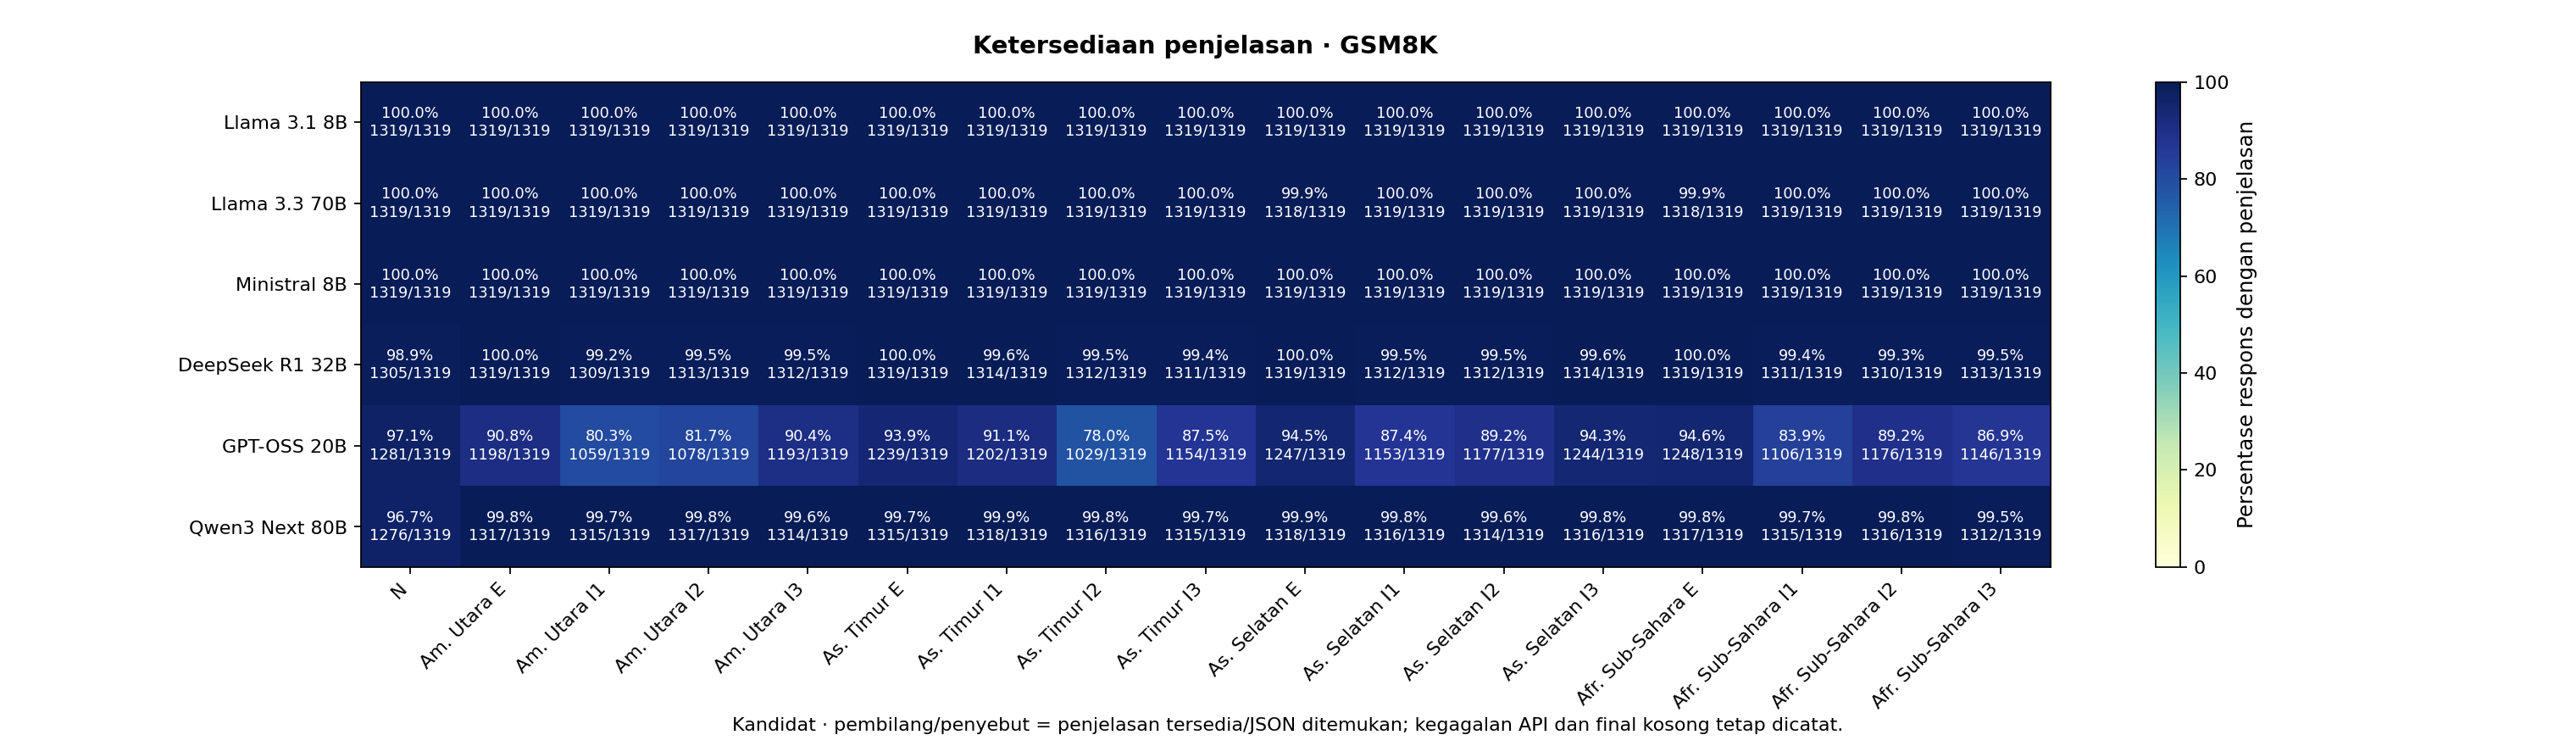

In [7]:
from PIL import Image as PILImage
for entry in figure_index:
    with PILImage.open(FIGURES/entry['file']) as im:
        im.verify()
assert len(list(FIGURES.glob('*.png')))==len(figure_index)
assert not list(FIGURES.glob('*.svg'))
assert statistics.groupby('model_id').size().eq(family_size).all()
assert pair_support.explanation_pairs.le(pair_support.question_pairs).all()
assert all(file_sha(ROOT/p)==h for p,h in SOURCE_HASHES.items() if p!='response_records_sha256')
summary={
 'benchmark':BENCHMARK,'run_id':RUN_ID,'status':SCIENTIFIC_STATUS,
 'rows':len(records),'raw_json_invalid':int(records.source_status.eq('invalid_json').sum()),
 'available_explanations':int(records.explanation_available.sum()),
 'pair_eligible_records':int(records.pair_eligible.sum()),
 'request_question_unverified':int((~records.request_question_verified).sum()),
 'duplicate_pair_key_records':int(records.duplicate_pair_key.sum()),
 'reasoning_only_records':int(records.reasoning_only.sum()),
 'original_id_question_mismatches_across_contrasts':int(pair_audit.old_id_question_mismatch.sum()),
 'figures':len(figure_index),'markers':len(MARKER_IDS),'outcomes':len(OUTCOMES),
 'holm_hypotheses_per_model':family_size,'source_hashes':SOURCE_HASHES,
 'marker_dictionary_changed':False,'answer_scoring_changed':False,'reasoning_used':False,
 'derived_metrics_policy':'current_surface_and_integer_counts_full_precision',
 'analysis_replay_from':globals().get('ANALYSIS_REPLAY_SOURCE'),
 'human_audit_passed':False,'notebook_source':NOTEBOOK_NAME,
 'numeric_test':'signed-rank exact conditional sign permutation k<=20; normal approximation otherwise',
 'binary_test':'exact conditional McNemar','bootstrap':'surface paired mean only, 2000, fixed observed subset weights',
 'scientific_limits':['Semantic marker audit incomplete; known contextual false positives and misses remain','Implicit condition changes dialogue history as well as identity expression',
  'Available-explanation selection differs by model/persona','Pooled ETHICS is pair-weighted, not equal-subset weighted',
  'GSM8K and ETHICS frozen dictionaries and surfaces are not identical; do not equate raw prevalence across benchmarks'],
}
(RUN/'manifest.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
notes=f"""# Linguistic marker regional — {BENCHMARK}
Tanggal: 2026-10-05. Status: **kandidat; audit semantik belum tuntas; ada kesalahan marker yang diketahui**.

## Lokasi
Notebook aktif: {NOTEBOOK_NAME}. PNG aktif: figures/. Sumber lengkap keluaran ini: {RUN}.
Tidak ada HTML/SVG baru. Hasil lama disimpan di _arsip/, bukan dihapus.
Run All membaca seluruh korpus yang tersedia, membuat direktori hasil baru, lalu memasang gambar setelah pemeriksaan lolos.

## Yang berubah
- Pairing memakai isi soal yang cocok dengan dataset dan terverifikasi muncul dalam pesan pengguna terakhir. Nomor file saja tidak cukup.
- GSM8K memakai seluruh 1.319 soal test; ETHICS memakai seluruh 1.514 soal dalam eksperimen empat subset, bukan seluruh benchmark ETHICS global.
- API final kosong tidak dipulihkan dari reasoning. Semua respons tetap diinventarisasi, tanpa filter committed/correct.
- Kamus dibekukan: {len(MARKER_IDS)} marker; definisi/regex tidak ditambah. Setiap sumber, definisi, dan pengecualian ada di registry.json.
- Densitas dan prevalensi dipisahkan. Jumlah mentah, densitas per 100 kata, dan kehadiran disimpan per respons.
- Seluruh 52 kontras/model tersedia: 16 persona–N, 12 I–E, 24 antaridentitas. Arah selalu **kiri dikurangi kanan**, tertulis di judul.
- Warna tidak dipudarkan berdasarkan p-value. Heatmap mencantumkan k/n, sel abu-abu untuk dukungan rendah, dan tanda signifikansi.
- Keluarga Holm yang sama mencakup seluruh {family_size:,} hipotesis terencana/model dalam paket benchmark ini, termasuk subset dan gabungan untuk ETHICS. Hipotesis tidak teruji tetap dihitung dalam ukuran keluarga, p-nya tetap NA.

## Membaca gambar
- **ND**: tidak ada pasangan penjelasan yang dapat dibandingkan. Bukan efek nol.
- **TP**: pasangan ada tetapi semua selisih nol; n tetap terlihat. Rank-biserial tidak terdefinisi dan tidak diubah menjadi nol. Untuk prevalensi, selisih aktual nol tetap tersedia di CSV.
- **k**: pasangan dengan selisih nonnol; **n**: pasangan penjelasan yang dibandingkan.
- Sel abu-abu/† atau segitiga: k<20, hanya penandaan dukungan rendah, bukan batas universal validitas.
- [F]: ukuran format literal log. Runner memakai pembersihan whitespace bahkan di field raw_api_response; newline tersimpan tidak selalu mewakili struktur respons asli. Jangan mengatribusikan perubahan ukuran [F] langsung kepada persona. Penghapusan baris jawaban teknis juga dapat memengaruhi denominator density, jumlah kata, dan TTR; audit surface tetap diperlukan.
- Bintang atau tepi hitam: p Holm<0,05.
- Rank-biserial dihitung dari peringkat selisih densitas per respons. Nilai ±1 tidak berarti perubahan luas; selalu baca k/n.
- Prevalensi: selisih persentase respons dengan marker, dalam poin persentase; uji McNemar eksak.
- Tepi hitam pada karakteristik berasal dari uji signed-rank/Holm, bukan uji terhadap rata-rata. CI yang melintasi nol tidak otomatis bertentangan dengan tanda signed-rank karena estimand berbeda.
- Garis CI pada karakteristik adalah CI **selisih rata-rata**, bukan CI rank-biserial. Bootstrap 2.000 kali pada pasangan; ETHICS gabungan distratifikasi subset dengan bobot pasangan tersedia. CI disembunyikan bila n<2, k<6, degenerat, atau strata berisi <2 pasangan.
- Profil semua marker bersifat deskriptif. Tidak menyiratkan signifikansi; semua efek inferensial tetap ada di CSV.

## Presisi metrik turunan
Cache hanya digunakan sebagai sumber count marker yang telah diverifikasi. Densitas dihitung kembali
dari count integer dan jumlah kata; karakteristik teks menggunakan surface saat ini. Rasio cache
yang pernah dibulatkan tidak dicampur dengan rasio baru berpresisi penuh.
Jika eksekusi adalah replay numerik, lihat derived_metric_precision_audit.csv dan
numeric_replay_provenance.json: teks final dan count tidak berubah, statistik dihitung ulang.
Replay saat ini: {globals().get('ANALYSIS_REPLAY_SOURCE') or 'tidak ada; lihat manifest/provenance visual bila tersedia'}.

## Kebijakan statistik dan perbandingan dengan paket lama
Ini bukan sekadar perubahan tata letak. Pasangan soal dan kanal teks diperbaiki.
Uji numerik kini diselaraskan dengan paket gender: signed-rank dua sisi, exact sign permutation pada k≤20 (mendukung ties), aproksimasi normal pada k>20.
Uji tanda disimpan sebagai sensitivitas dalam p_sign_sensitivity dan p_sign_holm.
Paket lama memiliki keluarga Holm lebih kecil; ETHICS memakai keluarga 3/4/24 dan visual selisih median dalam satuan asli. Estimand visual baru dan kebijakan koreksi berbeda.
Jadi p-value dan banyaknya tanda signifikan lama–baru **tidak boleh dibandingkan seolah hanya data yang berubah**.
Ukuran mean_delta, median_delta, n_pairs, n_nonzero, dan rank-biserial tersedia untuk penelaahan.
Tidak dibuat klaim bahwa ambang k atau satu p-value menjamin kualitas pengukuran.

## Keterbatasan yang tetap berlaku
1. Audit semantik kamus/parsing belum selesai; kesalahan konteks dan miss yang ditemukan audit sebelumnya BELUM diperbaiki oleh rebuild ini. Lihat marker_catalog.csv dan catatan audit. Gambar bukan hasil final siap tesis.
2. I–E membandingkan paket persona dan konteks percakapan; implicit dapat memiliki warmup assistant panjang. Bukan efek identitas murni. Lihat conversation_context.csv.
3. Kesimpulan hanya untuk penjelasan tersedia; cakupan rendah bukan bukti model tidak memiliki suatu ciri bahasa.
4. Efek ETHICS gabungan berbobot pasangan tersedia, bukan empat subset berbobot sama. Profil deskriptif gabungan berbobot penjelasan tersedia per skenario. Baca pair_support.csv dan pooled_subset_direction_check.csv; utamakan analisis subset.
5. Definisi kamus/surface antarbenchmark tidak sepenuhnya sama. Titik temu adalah 14 marker bahasa umum dan rancangan pelaporannya; marker spesifik tugas tidak dipaksakan identik.
6. Deontology pada eksperimen tidak memasukkan excuse; virtue menggunakan instruksi moral umum. Tidak ada perubahan scoring atau klaim akurasi gabungan.
7. Rujukan teori pada registry bukan bukti semua regex tervalidasi; kamus korpus/custom tetap kandidat.

## Audit marker yang belum dipromosikan
Registry dibekukan, bukan dinyatakan benar. Marker bertanda known_context_errors_or_misses mencakup
hedge, conditional, self-reference, framing konsekuensi, evaluasi moral negatif, meta-budaya,
relativisme, dan adopsi perspektif. Sebagian kata terpicu oleh ucapan tokoh/evaluasi teknis; sebagian
variasi Markdown atau frasa budaya terlewat. Probe diagnostik memindai seluruh korpus dan menyediakan
respons utuh untuk review, tetapi kolom review tetap not_reviewed. Sampel yang baru disiapkan bukan
sampel yang sudah diaudit. Tidak ada klaim reviewer manusia atau validasi independen.
Aturan ekstraksi semantik tidak ditambah; keluaran ini menyelesaikan perbaikan mekanis, bukan seluruh P2.

## Sensitivitas tambahan
Analisis utama mencakup seluruh penjelasan tanpa filter benar/committed. both_correct GSM8K dan
both_committed ETHICS memakai status parser beku sebagai sensitivitas saja, bukan penilaian baru.
ETHICS juga memeriksa histori implicit yang tersedia dan satu ID kanonis tetap per skenario unik
(pemilihan ID sebelum melihat respons). Keluarga Holm sensitivitas terpisah dari analisis utama.
Cochran Q memeriksa availability berpasangan antarpersona pada soal yang lengkap, dengan rentang
persentase sebagai ukuran deskriptif. Ini bukan pembuktian tidak adanya differential measurement error.
Lihat sensitivity_statistics.csv.gz, sensitivity_summary.csv, availability_persona_tests.csv.

## Tabel penting
- source_audit.csv: provenance tiap JSON, kanal, status pairing, dan konteks percakapan.
- pairing_audit.csv: perbandingan pairing nomor lama vs isi soal.
- response_records.csv.gz: seluruh pengukuran dan final text; tidak menyimpan reasoning tersembunyi.
- coverage.csv, pair_support.csv: denominator respons dan pasangan.
- outcome_registry.csv, paired_statistics.csv.gz: outcome, efek, dukungan, p mentah/Holm, metode, status CI.
- figure_index.csv: indeks semua PNG.
- manifest.json: hash sumber dan keterbatasan.
"""
(RUN/'README.md').write_text(notes,encoding='utf-8')
# Publish only after numerical, provenance and PNG checks pass. Preserve old assets.
archive=ACTIVE/'_arsip'/f'before_rebuild_{RUN_ID}'
archive.mkdir(parents=True,exist_ok=False)
active_figures=ACTIVE/'figures'
assert ACTIVE.resolve().is_relative_to((ROOT/'notebooks/regional/linguistic marker').resolve())
old_hashes={}
if active_figures.exists():
    old_hashes={str(p.relative_to(active_figures)):file_sha(p) for p in active_figures.rglob('*') if p.is_file()}
    shutil.move(str(active_figures),str(archive/'figures'))
    assert old_hashes=={str(p.relative_to(archive/'figures')):file_sha(p) for p in (archive/'figures').rglob('*') if p.is_file()}
shutil.copytree(FIGURES,active_figures)
for name in ['README.md','LATEST_RUN.json','figure_index.csv']:
    p=ACTIVE/name
    if p.exists():
        shutil.copy2(p,archive/name)
shutil.copy2(RUN/'README.md',ACTIVE/'README.md')
shutil.copy2(RUN/'figure_index.csv',ACTIVE/'figure_index.csv')
(ACTIVE/'LATEST_RUN.json').write_text(json.dumps({'run':str(RUN),'status':SCIENTIFIC_STATUS,'figures':len(figure_index),'archive':str(archive)},indent=2),encoding='utf-8')
(archive/'preserved_hashes.json').write_text(json.dumps(old_hashes,indent=2),encoding='utf-8')
shutil.copy2(ACTIVE/NOTEBOOK_NAME,RUN/'notebook_source.ipynb')
print('Pemeriksaan berhasil. PNG aktif:',active_figures)
print('Arsip lama:',archive)
print(json.dumps({k:summary[k] for k in ['rows','available_explanations','figures','original_id_question_mismatches_across_contrasts','status']},indent=2))
display(Image(filename=str(active_figures/f'00_cakupan_{SCOPES[0]}.png'),width=1200))


In [ ]:
# Optional visual-only refresh; Run All above still rebuilds the full raw corpus.
def refresh_figures_from_run(source_run, notebook_path, refresh_kinds=None):
    import json, shutil
    from pathlib import Path
    source_run=Path(source_run).resolve()
    notebook_path=Path(notebook_path).resolve()
    notebook=json.loads(notebook_path.read_text(encoding='utf-8'))
    cells={c['id']:''.join(c['source']) for c in notebook['cells'] if c['cell_type']=='code'}
    old_manifest=json.loads((source_run/'manifest.json').read_text(encoding='utf-8'))
    context={}
    exec(compile(cells['configuration'],'configuration','exec'),context)
    root=context['ROOT']; run=context['RUN']
    assert source_run.is_relative_to((root/'result/linguistic_markers').resolve())
    assert old_manifest['benchmark']==context['BENCHMARK']
    assert json.loads((source_run/'registry.json').read_text(encoding='utf-8'))==context['REGISTRY']
    context['VISUAL_ONLY_SOURCE']=str(source_run)
    if refresh_kinds is not None:
        context['REUSE_FIGURES_FROM']=source_run/'figures'
        context['REFRESH_KINDS']=set(refresh_kinds)
    context['SOURCE_HASHES']=old_manifest['source_hashes']
    for path in source_run.iterdir():
        if path.is_file() and path.name not in ['manifest.json','README.md','notebook_source.ipynb','figure_index.csv','marker_catalog.csv']:
            shutil.copy2(path,run/path.name)
            assert context['file_sha'](path)==context['file_sha'](run/path.name)
    pd=context['pd']
    context['OUTCOMES']=pd.read_csv(run/'outcome_registry.csv').to_dict('records')
    context['family_size']=old_manifest['holm_hypotheses_per_model']
    context['statistics']=pd.read_csv(run/'paired_statistics.csv.gz')
    context['sensitivity']=pd.read_csv(run/'sensitivity_statistics.csv.gz')
    context['sensitivity_specs']=[(name,g.scope.drop_duplicates().tolist()) for name,g in context['sensitivity'].groupby('sensitivity',sort=False)]
    for variable,filename in [('coverage','coverage.csv'),('pair_support','pair_support.csv'),
        ('pair_audit','pairing_audit.csv'),('format_summary','format_diagnostics.csv')]:
        context[variable]=pd.read_csv(run/filename)
    columns=['model_id','persona','subset','explanation_available','source_status','pair_eligible',
        'request_question_verified','duplicate_pair_key','reasoning_only']
    columns += [m+'__present' for m in context['MARKER_IDS']]
    context['records']=pd.read_csv(run/'response_records.csv.gz',usecols=columns)
    exec(compile(cells['png-figures'],'png-figures','exec'),context)
    exec(compile(cells['validate-and-publish'],'validate-and-publish','exec'),context)
    (run/'visual_refresh_provenance.json').write_text(json.dumps({
        'source_run':str(source_run),'source_manifest_sha256':context['file_sha'](source_run/'manifest.json'),
        'analysis_recomputed':False,'figures_regenerated':True,
        'png_regenerated':sum(r['render_source']=='regenerated' for r in context['figure_index']),
        'png_reused':sum(r['render_source']=='unchanged_previous_png' for r in context['figure_index']),
        'notebook_sha256':context['file_sha'](notebook_path)},indent=2),encoding='utf-8')
    return str(run)


In [ ]:
# Canonical numeric replay: counts/rules/raw texts stay frozen; derived metrics are recalculated.
def rebuild_derived_metrics_from_run(source_run, notebook_path):
    import ast, json, shutil
    from pathlib import Path
    source_run=Path(source_run).resolve()
    notebook_path=Path(notebook_path).resolve()
    notebook=json.loads(notebook_path.read_text(encoding='utf-8'))
    cells={c['id']:''.join(c['source']) for c in notebook['cells'] if c['cell_type']=='code'}
    previous=json.loads((source_run/'manifest.json').read_text(encoding='utf-8'))
    context={}
    exec(compile(cells['configuration'],'configuration','exec'),context)
    root=context['ROOT'];run=context['RUN'];pd=context['pd'];np=context['np']
    assert source_run.is_relative_to((root/'result/linguistic_markers').resolve())
    assert previous['benchmark']==context['BENCHMARK']
    assert json.loads((source_run/'registry.json').read_text(encoding='utf-8'))==context['REGISTRY']
    context['ANALYSIS_REPLAY_SOURCE']=str(source_run)
    context['SOURCE_HASHES']=dict(previous['source_hashes'])
    source_csv=source_run/'response_records.csv.gz'
    original_sha=context['file_sha'](source_csv)
    assert original_sha==previous['source_hashes']['response_records_sha256']
    keep=['source_audit.csv','coverage.csv','text_status_counts.csv','canonical_status_counts.csv',
        'conversation_context.csv','pairing_audit.csv','candidate_probe_counts.csv','format_diagnostics.csv',
        'candidate_probe_readback.jsonl','candidate_probe_audit_status.csv','cache_reproduction_checks.csv',
        'previous_source_comparison.csv']
    for name in keep:
        path=source_run/name
        if path.exists():
            shutil.copy2(path,run/name)
            assert context['file_sha'](path)==context['file_sha'](run/name)
    tree=ast.parse(cells['sources-and-unit-tests'])
    functions=[node for node in tree.body if isinstance(node,ast.FunctionDef)]
    exec(compile(ast.Module(body=functions,type_ignores=[]),'measurement-functions','exec'),context)
    numeric=['word_count','sentence_count','avg_sentence_length','ttr_300']+[m+'__'+suffix for m in context['MARKER_IDS'] for suffix in ['count','density','present']]
    records=pd.read_csv(source_csv,keep_default_na=False,na_values={c:[''] for c in numeric},
        dtype={c:float for c in numeric},float_precision='round_trip',low_memory=False)
    assert records.final_text.map(context['sha']).eq(records.final_text_hash).all()
    derived=['avg_sentence_length','ttr_300']+[m+'__density' for m in context['MARKER_IDS']]
    corrected=np.full((len(records),len(derived)),np.nan)
    columns=records.columns.tolist()
    for i,values in enumerate(records.itertuples(index=False,name=None)):
        row=dict(zip(columns,values))
        cached_metrics={column:row[column] for column in numeric}
        fresh=context['measure'](row['final_text'],cached_metrics)
        assert fresh['explanation_available']==row['explanation_available']
        assert fresh['analysis_text']==row['analysis_text']
        assert fresh['text_status']==row['text_status']
        for j,column in enumerate(derived):
            value=fresh[column]
            corrected[i,j]=np.nan if value is None else value
        if (i+1)%10000==0 or i+1==len(records):
            print('Kanonisasi metrik turunan:',i+1,'/',len(records),flush=True)
    old=records[derived].to_numpy(float)
    assert np.allclose(old,corrected,rtol=1e-5,atol=1e-6,equal_nan=True),'Change exceeds numeric precision; investigate before statistics.'
    precision=[]
    for j,column in enumerate(derived):
        finite=np.isfinite(old[:,j])&np.isfinite(corrected[:,j])
        changed=finite&(old[:,j]!=corrected[:,j])
        precision.append(dict(metric=column,values_checked=int(finite.sum()),values_changed=int(changed.sum()),
            max_absolute_change=float(np.max(np.abs(old[finite,j]-corrected[finite,j]))) if finite.any() else 0.))
    context['save_table'](pd.DataFrame(precision),'derived_metric_precision_audit.csv')
    records[derived]=corrected
    records['derived_metric_source']='current_surface_and_integer_counts'
    context['records']=records
    context['save_table'](records,'response_records.csv.gz')
    context['SOURCE_HASHES']['response_records_sha256']=context['file_sha'](run/'response_records.csv.gz')
    cache_checks=[]
    for model in context['MODELS']:
        pool=records[records.model_id.eq(model)&records.explanation_available&records.measurement_source.eq('verified_frozen_final_cache')]
        for row in pool.sample(n=min(10,len(pool)),random_state=context['SEED']).to_dict('records'):
            fresh=context['measure'](row['final_text'])
            differences=[m for m in context['MARKER_IDS'] if fresh[m+'__count']!=row[m+'__count']]
            cache_checks.append(dict(model_id=model,raw_source_file=row['raw_source_file'],marker_differences=';'.join(differences),
                word_count_matches=fresh['word_count']==row['word_count'],measurement_source=row['measurement_source']))
    context['save_table'](pd.DataFrame(cache_checks),'cache_only_reproduction_checks.csv')
    assert all(not r['marker_differences'] and r['word_count_matches'] for r in cache_checks)
    for variable,filename in [('coverage','coverage.csv'),('pair_audit','pairing_audit.csv'),('format_summary','format_diagnostics.csv')]:
        context[variable]=pd.read_csv(run/filename)
    for cell_id in ['paired-statistics','sensitivity','png-figures','validate-and-publish']:
        print('REPLAY',cell_id,flush=True)
        exec(compile(cells[cell_id],cell_id,'exec'),context)
    (run/'numeric_replay_provenance.json').write_text(json.dumps({
        'source_run':str(source_run),'source_response_records_sha256':original_sha,
        'raw_json_retraversed':False,'full_saved_final_texts_reprocessed':len(records),
        'marker_counts_changed':False,'marker_rules_changed':False,'derived_metrics_recalculated':True,
        'statistics_recomputed':True,'cache_only_reproduction_checks':len(cache_checks),
        'notebook_sha256':context['file_sha'](notebook_path)},indent=2),encoding='utf-8')
    return str(run)
